# **Community Structure of Complex Networks** 

**Authors:** Cindy Chen, Keith Megara Osores Vicuña 

**Master**: Health Data Science

**Subject**: Complex Networks   

**Course**: 2025-2026  

---

## **Table of Contents**

**1. [Network selection and its relevance](#section1)**   
&emsp; **1.1 [Macroscopic characterization](#section11)**   
&emsp; **1.2 [Microscopic characterization](#section12)**   
&emsp; **1.3 [Network visualization](#section13)**   
&emsp; **1.4 [Generative model](#section14)**   

**2. [Community detection](#section2)**     
&emsp; **2.1 [Community detection algorithms](#section21)**  
&emsp; &emsp; **2.1.1 [Modularity-maximization-based algorithms](#section211)**   
&emsp; &emsp; **2.1.2 [Infomap](#section212)**      
&emsp; &emsp; **2.1.3 [Degree corrected stochastic block model](#section213)**    
&emsp; **2.2 [Comparison of algorithm's performance](#section22)**

**3. [Analysis of detected communities](#section3)**  
&emsp; **3.1 [Louvain algorithm](#section31)**      
&emsp; **3.2 [Infomap](#section32)**   
&emsp; **3.3 [Degree corrected stochastic block model](#section33)**   

---

**Important note:** This notebook was run using Windows operation system, conda 4.12.0 version and Python 3.10.19 version. In this case, please, notice that to execute this code properly, an Ubuntu teminal must be installed. Then, a virtual environment "graphs" must be created to install the dependencies (packages) included in the text file titled "requirements.txt", which can be achieved by running the following command: ```pip install -r /path/to/requirements.txt``` (changing /path/to/ to your path to .txt file). In addition, the package ```graph-tool``` (not inherent from Python) must be installed via the ```sudo apt-get install python3-graph-tool``` command following the steps explained in the installation process for Windows (available in https://graph-tool.skewed.de/installation.html#debian-ubuntu). The graph tool version used was 1.14.

<a id='section1'></a>
## **1. Network selection and its relevance** 

For this assignment, we selected the Malaria var DBLa HVR1 network from the malaria_genes dataset available on the Netzschleuder network repository: https://networks.skewed.de/net/malaria_genes  

This network represents genetic relationships between Plasmodium falciparum var genes, which encode the PfEMP1 protein (a key factor in immune evasion and pathogenicity of malaria).   

Each node corresponds to a var gene sequence, and edges denote significant similarities between their highly variable DBLa domains.   

We chose this network because it is biologically meaningful and large enough (over 200 nodes) to exhibit complex community structure. Identifying communities within this network can reveal potential functional modules or evolutionary clusters of genes that contribute to different immune responses or virulence profiles in malaria infections, making it a compelling case for community detection analysis.

In [1]:
# Import necessary libraries
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import networkx as nx
import igraph as ig
import leidenalg as la
from infomap import Infomap
import graph_tool.all as gt
from graph_tool.draw import graph_draw

import statistics
from collections import Counter
import re
from scipy.stats import linregress


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\ProgramData\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\ProgramData\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\ProgramData\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\ProgramData\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\ProgramData\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\ProgramData\anaconda3\Lib\site-pack

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\ProgramData\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\ProgramData\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: DLL load failed while importing _path: The specified module could not be found.

In [2]:
# Import the network data
base_path = "HVR_1"
print(f"Current files' path: {base_path}")

# Files in the folder
files = os.listdir(base_path)

for file in files:
    if file.endswith((".csv")):
        file_path = os.path.join(base_path, file)
        df = pd.read_csv(file_path, sep="\t")
        print(f"- {file}: ({df.shape[0]}, {df.shape[1]})")
        display(df.head(4))

Current files' path: HVR_1
- edges.csv: (2812, 1)


,"# source, target"
0,"0,15"
1,"0,18"
2,"0,36"
3,"0,39"


- gprops.csv: (5, 1)


,"# prop_name, value"
0,"name,malaria_genes (HVR_1)"
1,"description,""Networks of recombinant antigen g..."
2,"citation,""['D. B. Larremore, A. Clauset, and C..."
3,"url,https://github.com/dblarremore/data_malari..."


- nodes.csv: (307, 1)


,"# index, name, CysPoLV, UPS, _pos"
0,"0,1,3,1,""array([14.72026042, -6.59973751])"""
1,"1,2,3,1,""array([14.84364571, -7.53487945])"""
2,"2,3,1,1,""array([14.79044458, -7.41367313])"""
3,"3,4,1,1,""array([14.82486019, -7.19602099])"""


In [3]:
print(files)

# Read nodes
nodes = pd.read_csv(os.path.join(base_path, files[2]))
print("Initial column names from nodes file: ", list(nodes.columns))

# Read edges
edges_df = pd.read_csv(os.path.join(base_path, files[0]))
print("Initial column names from edges file: ", list(edges_df.columns))

['edges.csv', 'gprops.csv', 'nodes.csv']
Initial column names from nodes file:  ['# index', ' name', ' CysPoLV', ' UPS', ' _pos']
Initial column names from edges file:  ['# source', ' target']


In [ ]:
# Rename columns
nodes.rename(columns={"# index": "index"}, inplace=True)
nodes.rename(columns={" CysPoLV": "CysPoLV"}, inplace=True)
nodes.rename(columns={" UPS": "UPS"}, inplace=True)
nodes.rename(columns={" _pos": "pos"}, inplace=True)
print("Modified column names from nodes file: ", list(nodes.columns))

edges_df.rename(columns={"# source": "source"}, inplace=True)
edges_df.rename(columns={" target": "target"}, inplace=True)
print("Modified column names from edges file: ", list(edges_df.columns))

nodes_df = nodes[["index", "pos"]]
print("\n", nodes_df.head(4))
print("\n", nodes_df.tail(4))
print(
    "\nThere are a total of {} nodes and {} edges in our chosen biological network.".format(
        nodes_df.shape[0], edges_df.shape[0]
    )
)

Modified column names from nodes file:  ['index', ' name', 'CysPoLV', 'UPS', 'pos']
Modified column names from edges file:  ['source', 'target']

    index                                pos
0      0  array([14.72026042, -6.59973751])
1      1  array([14.84364571, -7.53487945])
2      2  array([14.79044458, -7.41367313])
3      3  array([14.82486019, -7.19602099])

      index                                pos
303    303  array([15.46126975, -7.25160737])
304    304  array([15.35661573, -7.23410627])
305    305  array([15.3441845 , -7.18134607])
306    306  array([15.48706209, -7.31374593])

There are a total of 307 nodes and 2812 edges in our chosen biological network.


In [5]:
# Create a dictionary (with the position of the nodes for the input of networkx)
nodes_position = dict(zip(nodes_df["index"], nodes_df["pos"]))

# Convert string "array([x, y])" to tuple (x, y)
pos = {}
for k, v in nodes_position.items():
    # Extract numbers between brackets
    nums = re.findall(r"[-+]?\d*\.\d+|\d+", v)
    pos[k] = (float(nums[0]), float(nums[1]))

print("Position from the first node: ", pos.get(0))

Position from the first node:  (14.72026042, -6.59973751)


<a id='section11'></a>
### **1.1 Macroscopic characterization**

In [ ]:
# Create the network
G = nx.from_pandas_edgelist(edges_df, source="source", target="target")cle

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 307
Number of edges: 2812


In [ ]:
# Convert to simple graph if it's a MultiGraph
if isinstance(G, (nx.MultiGraph, nx.MultiDiGraph)):
    G = nx.Graph(G)

# For disconnected networks, some centrality metrics fail. Therefore, the largest connected component is used instead
if not nx.is_connected(G):
    largest_cc = max(nx.connected_components(G), key=len)
    G = G.subgraph(largest_cc).copy()

# Searching for the node with lowest and highest degree
lowest_degree_node = min(G.nodes, key=G.degree)
highest_degree_node = max(G.nodes, key=G.degree)

# The minimum and maximum degrees
lowest_degree = G.degree(lowest_degree_node)
highest_degree = G.degree(highest_degree_node)

# Using numpy.mean() to compute mean of dictionary values
mean_degree = np.mean([G.degree(node) for node in G.nodes()])

# Median degree
degree_sequence = [G.degree(n) for n in G.nodes]
median_degree = statistics.median(degree_sequence)

print(
    f"The minimum degree of the network is {lowest_degree:.4f}.\nThe maximum degree of the network is {highest_degree:.4f}"
)
print(
    f"The average degree of the network is {mean_degree:.4f}.\nThe median degree of the network is {median_degree:.4f}."
)

# Clustering coefficient
clustering_coefficients = nx.clustering(G)

# Identify the node with the minimum clustering coefficient
min_clustering_node = min(G.nodes, key=clustering_coefficients.get)
min_clustering_value = clustering_coefficients[min_clustering_node]

# Identify the node with the maximum clustering coefficient
max_clustering_node = max(G.nodes, key=clustering_coefficients.get)
max_clustering_value = clustering_coefficients[max_clustering_node]

print(
    f"Node {min_clustering_node} has the minimum clustering coefficient: {min_clustering_value:.4f}"
)
print(
    f"Node {max_clustering_node} has the maximum clustering coefficient: {max_clustering_value:.4f}"
)

# Average clustering coefficient
average_clustering_coefficient = nx.average_clustering(G)
print("The average clustering coefficient is %.4lf" % average_clustering_coefficient)

# Network assortativity
r = nx.degree_assortativity_coefficient(G)
print("Degree assortativity: %.4lf" % r)

# Average shortest path length (average shortest distance between all pairs of nodes)
avg_path_length = nx.average_shortest_path_length(G)
print("Average path length: %.4lf" % avg_path_length)

# Network diameter (maximum distance between nodes in the network)
diam = nx.diameter(G)
print(f"Diameter: {diam}")

The minimum degree of the network is 1.0000.
The maximum degree of the network is 55.0000
The average degree of the network is 18.3192.
The median degree of the network is 16.0000.
Node 80 has the minimum clustering coefficient: 0.0000
Node 44 has the maximum clustering coefficient: 1.0000
The average clustering coefficient is 0.5702
Degree assortativity: 0.5991
Average path length: 3.5191
Diameter: 8


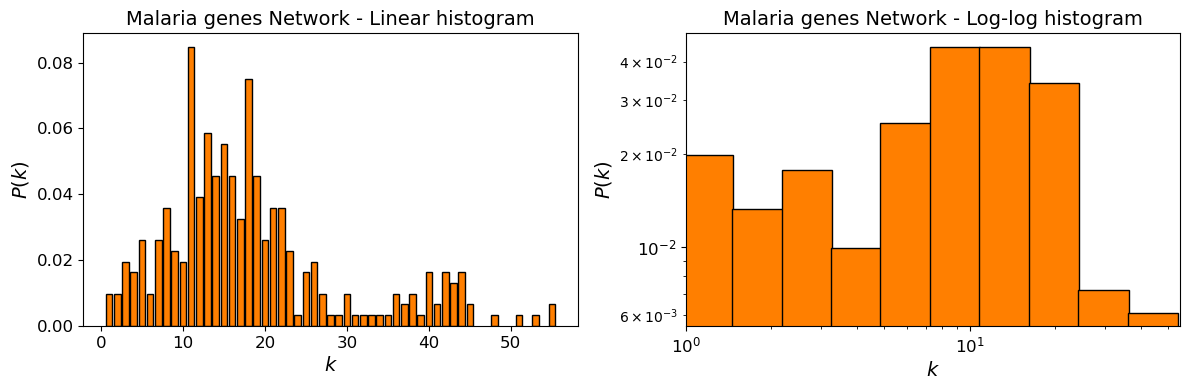

Malaria genes Network: γ = 0.099, R² = 0.028


In [ ]:
# Degree sequence
degrees = np.array([G.degree(n) for n in G.nodes() if G.degree(n) > 0])
n = len(degrees)

# Linear histogram
degree_counts = Counter(degrees)
k = np.array(sorted(degree_counts.keys()))
pk = np.array([degree_counts[ki] / n for ki in k])

# Logarithmic binning
bins_log = 10
kmin, kmax = degrees.min(), degrees.max()
bins = np.logspace(np.log10(kmin), np.log10(kmax), bins_log + 1)
hist, bin_edges = np.histogram(degrees, bins=bins, density=False)

# Normalize to probability density
bin_widths = np.diff(bin_edges)
pk_log = hist / (n * bin_widths)
k_log = np.sqrt(bin_edges[1:] * bin_edges[:-1])

# Compute slope (γ)
mask = pk_log > 0
x = np.log10(k_log[mask])
y = np.log10(pk_log[mask])
slope, intercept, r_value, _, _ = linregress(x, y)
gamma = -slope
r2 = r_value**2

# Plot
network_title = f"Malaria genes Network"

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Linear histogram
ax[0].bar(k, pk, width=0.8, color="#ff7f00", edgecolor="black")
ax[0].set_xlabel("$k$", fontsize=14)
ax[0].set_ylabel("$P(k)$", fontsize=14)
ax[0].set_title(f"{network_title} - Linear histogram", fontsize=14)
ax[0].tick_params(axis="both", labelsize=12)

# Log–log histogram
ax[1].bar(
    k_log, pk_log, width=bin_widths, color="#ff7f00", edgecolor="black", align="center"
)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("$k$", fontsize=14)
ax[1].set_ylabel("$P(k)$", fontsize=14)
ax[1].set_title(f"{network_title} - Log-log histogram", fontsize=14)
ax[1].tick_params(axis="both", labelsize=12)
ax[1].set_xlim(bin_edges[0], bin_edges[-1])

fig.tight_layout()
plt.show()

print(f"{network_title}: γ = {gamma:.3f}, R² = {r2:.3f}")

**Interpretation:**

From the linear scale histogram, we can see how the degree frequency P(k) rises sharply for small k (low-degree nodes), peaks between roughly $k \approx 10–20$, and then decays gradually with a long tail extending to $k \approx 50–55$. This means that most nodes have a few connections, but a small number of nodes have much higher degree.

As for the log-log histogram, the distribution does not appear as a straight line (which would indicate a perfect power-law). Instead, it curves downward and shows irregular bins. This suggests that although there is a heavy tail, it’s not a pure scale-free (power-law) behaviour. Additionally, the $R^2$ value is very low, so a power-law fit is poor, thus, the degree distribution does not follow a strict power-law. The small $\gamma (\approx 0.1)$ is inconsistent with typical scale-free exponents (2 < γ < 3), further confirming that a power-law model doesn’t fit well here.

To summarize:

- The network is heterogeneous (many low-degree nodes and a few hubs).  

- However, it’s not scale-free in the strict mathematical sense (low $R^2$).  

- The long tail suggests some hub nodes exist, but their frequencies drop faster than a true power-law.  

This shape is often seen in biological interaction networks where experimental bias or limited sampling creates an approximately heavy-tailed but truncated distribution.

<a id='section12'></a>
### **1.2 Microscopic characterization**

In [ ]:
# Degree centrality (normalized by default)
degree_centrality = nx.degree_centrality(G)

# Betweenness centrality
betweenness_centrality = nx.betweenness_centrality(G)

# Closeness centrality
closeness_centrality = nx.closeness_centrality(G)
min_closeness_node = min(G.nodes, key=closeness_centrality.get)
min_closeness = closeness_centrality[min_closeness_node]
max_closeness_node = max(G.nodes, key=closeness_centrality.get)
max_closeness = closeness_centrality[max_closeness_node]

print(
    f"  Minimum closeness value of {min_closeness:.4f} comes from node {min_closeness_node}."
)
print(
    f"  Maximum closeness value of {max_closeness:.4f} comes from node {max_closeness_node}.\n"
)

# Eigenvector centrality
eigenvector_centrality = nx.eigenvector_centrality(G)

# Create function for top centrility nodes


def print_top_nodes(metric_name, centrality_dict):
    """
    Function that prints the top five nodes based on a specific centrality measurement.
    """
    sorted_nodes = sorted(
        centrality_dict, key=lambda node: centrality_dict[node], reverse=True
    )
    top_five = sorted_nodes[:5]
    print(f"Top 5 nodes by {metric_name} centrality:")
    for node in top_five:
        print(f"  Node {node}: {centrality_dict[node]:.4f}")
    print()


# Call the function for specific centrality's measurements
print_top_nodes("Degree", degree_centrality)
print_top_nodes("Betweenness", betweenness_centrality)
print_top_nodes("Eigenvector", eigenvector_centrality)

  Minimum closeness value of 0.1852 comes from node 57.
  Maximum closeness value of 0.4000 comes from node 293.

Top 5 nodes by Degree centrality:
  Node 256: 0.1797
  Node 272: 0.1797
  Node 262: 0.1732
  Node 119: 0.1667
  Node 102: 0.1569

Top 5 nodes by Betweenness centrality:
  Node 178: 0.1049
  Node 293: 0.0999
  Node 269: 0.0935
  Node 204: 0.0906
  Node 288: 0.0771

Top 5 nodes by Eigenvector centrality:
  Node 262: 0.1775
  Node 256: 0.1763
  Node 272: 0.1763
  Node 119: 0.1736
  Node 248: 0.1662



**Summary table of the network's descriptors:**

| **Descriptor**                     | **Characteristics of the chosen network**|                                
| ---------------------------------- | ------------------------------|
| **Number of nodes**                |    307                        |
| **Number of edges**                |    2,812                      |
| **Minimum degree**                 |    1                          |
| **Maximum degree**                 |    55                         |
| **Average degree**                 |    18.3192                    |
| **Median degree**                  |    16                         |
| **Degree distribution**            |    Bell-shaped curve          |
| **Average clustering coefficient** |    0.5702                     |
| **Assortativity**                  |    0.5991                     |
| **Average path length**            |    3.5191                     |
| **Diameter**                       |    8                          |
| **Top central nodes**              |  256, 272, 262 and 119        |
| **Log-log fitted metrics**         | $\gamma=0.099 $, $R^2=0.028 $ |

<a id='section13'></a>
### **1.3 Network visualization**

We will compare the complete network and its Largest Connected Component (LCC).

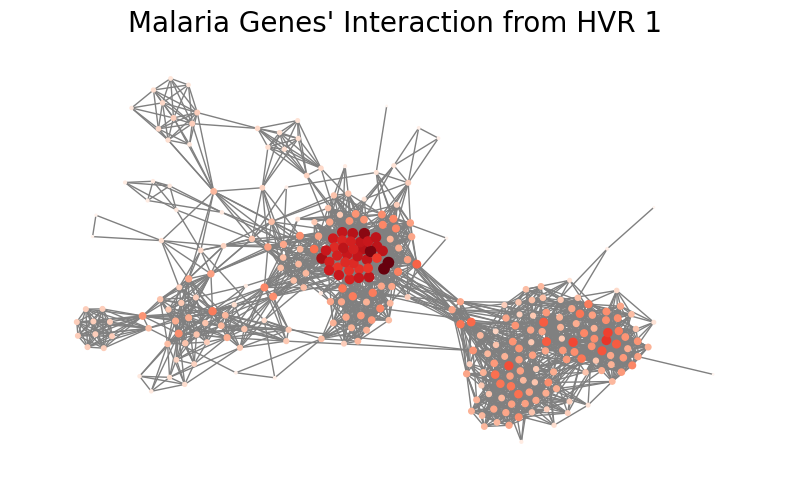

In [ ]:
# Create the network from the original csv file
G = nx.from_pandas_edgelist(edges_df, source="source", target="target")

# Convert it to a simple graph if it's a MultiGraph
if isinstance(G, (nx.MultiGraph, nx.MultiDiGraph)):
    G = nx.Graph(G)

# Define node styling
# Color the nodes by their degree centrality
color_nodes = [degree_centrality[node] for node in G.nodes()]
sizes_nodes = [G.degree(node) for node in G.nodes()]  # size equal to degree

# Plot the network
plt.figure(figsize=(8, 5))
nx.draw_networkx(
    G,
    pos=pos,
    node_size=sizes_nodes,
    node_color=color_nodes,
    edge_color="grey",
    width=1,
    with_labels=False,
    font_size=20,
    cmap="Reds",
)

plt.title("Malaria Genes' Interaction from HVR 1", fontsize=20)
plt.axis("off")
plt.box(False)
plt.tight_layout()
plt.show()

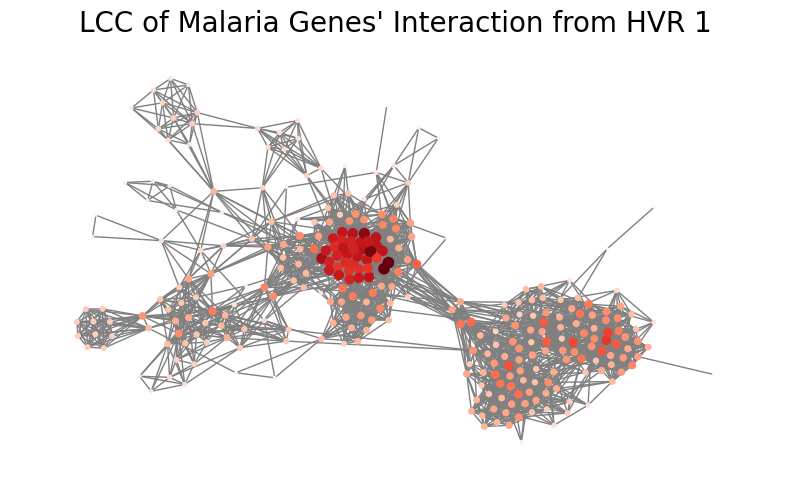

In [ ]:
# Use the largest connected component for visualization
if not nx.is_connected(G):
    largest_cc = max(nx.connected_components(G), key=len)
    G = G.subgraph(largest_cc).copy()

# Plot the LCC of the network
plt.figure(figsize=(8, 5))
nx.draw_networkx(
    G,
    pos=pos,
    node_size=sizes_nodes,
    node_color=color_nodes,
    edge_color="grey",
    width=1,
    with_labels=False,
    font_size=20,
    cmap="Reds",
)

plt.title("LCC of Malaria Genes' Interaction from HVR 1", fontsize=20)
plt.axis("off")
plt.box(False)
plt.tight_layout()
plt.show()

The network is fully connected, as the largest connected component (LCC) is the same as the entire network.

<a id='section14'></a>
### **1.4 Generative model**

Models studied in theory:

- Erdős–Rényi (ER) model
- Watts–Strogatz (WS) model with an intermediate rewiring probability
- Barabási–Albert (BA) model
- Configuration model (CM) assuming a degree distribution which follows a power-law with <2.5

**Which model best fit the chosen biological network from those mentioned above?**

Watts–Strogatz (WS) with an intermediate rewiring probability is the best match.

**Reasoning:**

- The degree distribution is bell-shaped (not heavy-tailed): rules out BA and a power-law CM (both produce heavy tails). ER can give a bell shape, but see below.

- High average clustering ($\approx 0.57$): ER and standard CM produce very low clustering. BA typically has low clustering unless specially modified. High clustering is a signature of WS (ring lattice + limited rewiring).

- Positive assortativity ($\approx 0.60$): ER and BA usually give assortativity near 0 or negative. WS often shows positive assortativity because nodes connect to neighbors of similar degree in the lattice.

- **Short average path length ($\approx 3.5$) and small diameter (8): combination of high clustering and short path length is exactly the small-world property WS was designed to produce (for intermediate rewiring p).**

- Poor power-law fit ($\gamma \approx 0.099, R^2 \approx 0.028$): confirms the network is not scale-free, so BA / power-law CM are unlikely.

**All in all, it strongly points towards a Watts–Strogatz network with moderate p rather than ER, BA, or a power-law configuration model.**

---
<a id='section2'></a>
## **2. Community detection**

First of all, we plot the reference partitions from two variables (CysPoLV and UPS) according to our network so that in the final section, we compare it with the inferred communities from the best modularity-based algorithm, Infomap and Degree corrected Stochastic Block Model.  

This network provides two types of classifications:  

- cys/PoLV:  Six DBLα classification groups based on cysteine counts (2 or 4 residues -cys2/cysX-) and Position of Limited Variability (PoLV) motifs numbered from 1 to 6, being the same as in all HVR networks (HVR1 included).  

- UPS: It stands for Upstream Promoter Regions. There are 4 classes (-1, 1, 2 and 3). The labels 1, 2, and 3 correspond to  UPS groups A, B, and C, respectively. Since some sequences did not have any UPS identified, they were labeled -1 (E/“NaN”).

In [ ]:
metadata_cys_unord = nodes[["index", "CysPoLV"]]
metadata_cys = metadata_cys_unord.sort_values(
    by=["CysPoLV", "index"], ascending=[True, True]
).reset_index(drop=True)

metadata_ups_unord = nodes[["index", "UPS"]]
metadata_ups = metadata_ups_unord.sort_values(
    by=["UPS", "index"], ascending=[True, True]
).reset_index(drop=True)

print(
    "These are our reference partitions:\n",
    metadata_cys.head(4),
    "\n",
    metadata_ups.head(4),
)

These are our reference partitions:
    index  CysPoLV
0      2        1
1      3        1
2      4        1
3      5        1 
    index  UPS
0      8   -1
1     27   -1
2     28   -1
3     88   -1


In [13]:
classes_cys = metadata_cys["CysPoLV"].value_counts(sort=False, ascending=True)
classes_cys_df = classes_cys.to_frame().reset_index()
classes_cys_df.columns = ["community", "count"]
communities_cys = classes_cys_df["community"].tolist()
print(classes_cys_df)

classes_ups = metadata_ups["UPS"].value_counts(sort=False, ascending=True)
classes_ups_df = classes_ups.to_frame().reset_index()
classes_ups_df.columns = ["community", "count"]
communities_ups = classes_ups_df["community"].tolist()
print(classes_ups_df)
print(type(classes_cys_df))

   community  count
0          1     33
1          2     24
2          3     40
3          4    176
4          5     21
5          6     13
   community  count
0         -1     15
1          1     63
2          2    168
3          3     61
<class 'pandas.core.frame.DataFrame'>


Based on CysPoLV, there are 6 communities (reference partitions): [1, 2, 3, 4, 5, 6].


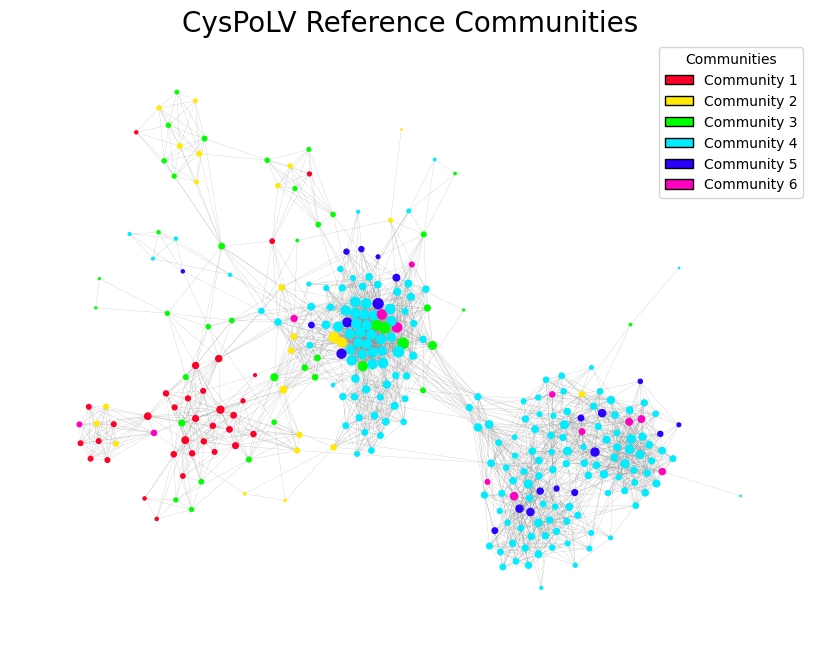

In [ ]:
# Dictionary with node ("index") and its class
community_node_cys = dict(zip(metadata_cys["index"], metadata_cys["CysPoLV"]))
number_communities_cys = len(classes_cys_df["community"])
print(
    f"Based on CysPoLV, there are {number_communities_cys} communities (reference partitions): {communities_cys}."
)

# Get sorted unique class labels
unique_vals = sorted(set(community_node_cys.values()))

# Updating mapping to display real reference partition names
mapping = {old: new for new, old in enumerate(unique_vals)}

# Re-indexed community assignment
community_node_cys_enumerate = {k: mapping[v] for k, v in community_node_cys.items()}

# Create colors for each community
colors = plt.cm.gist_rainbow(np.linspace(0, 1, number_communities_cys))

# Assign colors to real labels
label_to_color = {old: colors[mapping[old]] for old in unique_vals}

# Node colors
nodes_color = [label_to_color[community_node_cys[node]] for node in G.nodes()]

# Node sizes
nodes_sizes = [G.degree(node) for node in G.nodes()]

# Legend elements using original labels
legend_elements = [
    Patch(
        facecolor=label_to_color[label], edgecolor="black", label=f"Community {label}"
    )
    for label in unique_vals
]

# Plot
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    node_size=nodes_sizes,
    node_color=nodes_color,
    pos=pos,
    edge_color="grey",
    width=0.1,
)
plt.legend(handles=legend_elements, title="Communities", loc="best")
plt.title("CysPoLV Reference Communities", fontsize=20)
plt.show()

In [15]:
print((pd.Series(community_node_cys)).value_counts())

4    176
3     40
1     33
2     24
5     21
6     13
Name: count, dtype: int64


Based on UPS, there are 4 communities (reference partitions): [-1, 1, 2, 3].


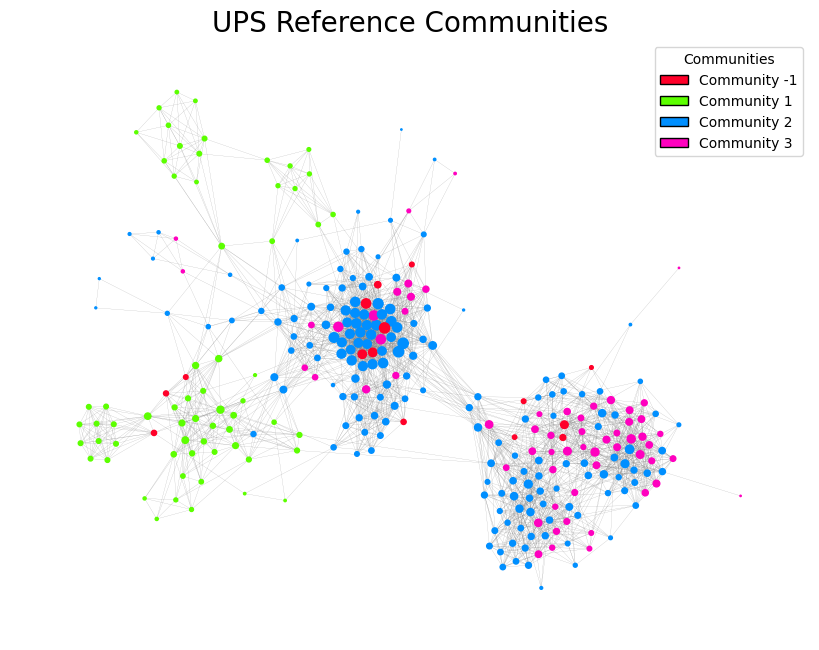

In [ ]:
# Dictionary with node ("index") and its class
community_node_ups = dict(zip(metadata_ups["index"], metadata_ups["UPS"]))
number_communities_ups = len(classes_ups_df["community"])
print(
    f"Based on UPS, there are {number_communities_ups} communities (reference partitions): {communities_ups}."
)

# Get sorted unique class labels
unique_vals = sorted(set(community_node_ups.values()))

# Updating mapping to display real reference partition names
mapping = {old: new for new, old in enumerate(unique_vals)}

# Re-indexed community assignment
community_node_ups_enumerate = {k: mapping[v] for k, v in community_node_ups.items()}

# Create colors for each community
colors = plt.cm.gist_rainbow(np.linspace(0, 1, number_communities_ups))

# Assign colors to real labels
label_to_color = {old: colors[mapping[old]] for old in unique_vals}

# Node colors
nodes_color = [label_to_color[community_node_ups[node]] for node in G.nodes()]

# Node sizes
nodes_sizes = [G.degree(node) for node in G.nodes()]

# Legend elements using original labels
legend_elements = [
    Patch(
        facecolor=label_to_color[label], edgecolor="black", label=f"Community {label}"
    )
    for label in unique_vals
]

# Plot
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    node_size=nodes_sizes,
    node_color=nodes_color,
    pos=pos,
    edge_color="grey",
    width=0.1,
)
plt.legend(handles=legend_elements, title="Communities", loc="best")
plt.title("UPS Reference Communities", fontsize=20)
plt.show()

In [17]:
print((pd.Series(community_node_ups)).value_counts())

 2    168
 1     63
 3     61
-1     15
Name: count, dtype: int64


<a id='section21'></a>
### **2.1 Community detection algorithms**

<a id='section211'></a>
#### **2.1.1 Modularity-maximization-based algorithms**

**Greedy algorithm**  

It iteratively builds communities by making the best local merges that most improve a quality measure, such as modularity (as for this analysis). Starting from single-node communities, it repeatedly chooses the merge with the highest immediate gain until no further improvement is possible. It is fast and scalable but may miss the global optimum.

The number of communities found with the greedy modularity algorithm is: 5


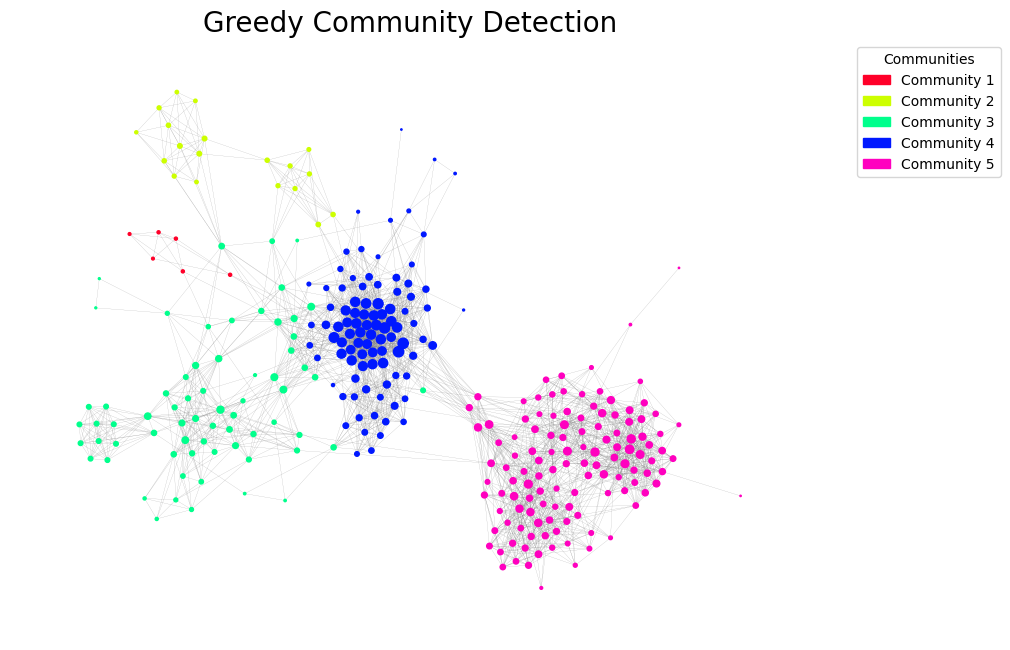

In [ ]:
# Create a set with the composition of each community
communities_greedy = nx.community.greedy_modularity_communities(G)
print(
    "The number of communities found with the greedy modularity algorithm is:",
    len(communities_greedy),
)

# We assign the community to each node
community_node_greedy = {}
count_community = 0

# Sort the detected communities by length
communities_list = [i for i in communities_greedy]
communities_list = tuple(sorted(communities_list, key=len))

# Assign their community label to each node
for community in communities_list:
    for node in community:
        community_node_greedy[node] = count_community
    # Change label when moving to the next community
    count_community = count_community + 1

# Create a color map to visualize the communities
number_communities_greedy = len(communities_list)
colors_greedy = plt.cm.gist_rainbow(np.linspace(0, 1, number_communities_greedy))

# Assign color per node
nodes_color_greedy = [colors_greedy[community_node_greedy[node]] for node in G.nodes()]

# Create legend
legend_handles = [
    Patch(color=colors_greedy[i], label=f"Community {i + 1}")
    for i in range(number_communities_greedy)
]

# Plot
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    node_size=nodes_sizes,
    node_color=nodes_color_greedy,
    pos=pos,
    edge_color="grey",
    width=0.1,
)
plt.legend(
    handles=legend_handles,
    title="Communities",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)
plt.title("Greedy Community Detection", fontsize=20)
plt.show()

**Louvain algorithm**  

It is a more structured and hierarchical Greedy algorithm that detects communities by repeatedly optimizing modularity in two phases. First, each node is moved to the neighbouring community that gives the highest modularity gain. Second, the detected communities are collapsed into super-nodes, forming a reduced graph, and the process repeats. This approach is fast and scalable, as the Greedy algorithm, but it is also effective for large networks (especially robust with heterogeneous networks).

In [ ]:
# List of seeds to test
seed_trial = range(1600, 1701)

best_modularity_lv = -1
best_seed = None
best_partition = None

for SEED in seed_trial:
    # Run Louvain
    communities_lv = nx.community.louvain_communities(G, seed=SEED)

    # Compute modularity
    Q = nx.community.modularity(G, communities_lv)

    # Track the best modularity
    if Q > best_modularity_lv:
        best_modularity_lv = Q
        best_seed = SEED
        best_partition = communities_lv

print(
    f"\nBest seed: {best_seed} with modularity = {best_modularity_lv:.4f} and {len(best_partition)} communities"
)


Best seed: 1692 with modularity = 0.6399 and 8 communities


When running from range(1, 2001), the output gives 2 results:
- Best seed: 144 with modularity = 0.6398 and 8 communities
- Best seed: 1692 with modularity = 0.6399 and 8 communities

Both seeds render equal communities in the final visualization, however, we select the seed with highest modularity, which is 1692.

The number of communities found with the Louvain modularity algorithm is: 8


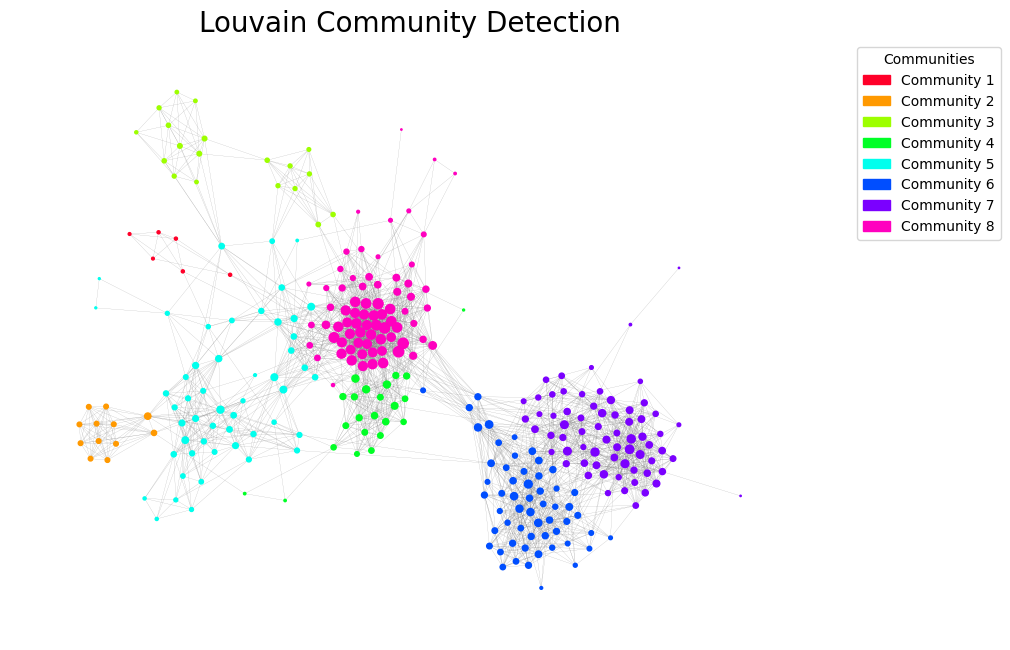

In [ ]:
BEST_SEED_LV = 1692

# Returns a set with the composition of each community
communities_louvain = nx.community.louvain_communities(G, seed=BEST_SEED_LV)
print(
    "The number of communities found with the Louvain modularity algorithm is:",
    len(communities_louvain),
)

# Create empty dictionary to add each node with its community
community_node_louvain = {}

# A simple way to label community from 0 to ncommunities-1
count_community = 0

# Sort the detected communities by length
communities_list = [i for i in communities_louvain]
communities_list = tuple(sorted(communities_list, key=len))

# Assign their community label to each node
for community in communities_list:
    for node in community:
        community_node_louvain[node] = count_community
    # Change label when moving to the next community
    count_community = count_community + 1

# Now we can create a color map to visualize the communities
number_communities_louvain = len(communities_list)
colors_louvain = plt.cm.gist_rainbow(np.linspace(0, 1, number_communities_louvain))

# Assign color per node
nodes_color_louvain = [
    colors_louvain[community_node_louvain[node]] for node in G.nodes()
]

# Create legend
legend_handles = [
    Patch(color=colors_louvain[i], label=f"Community {i + 1}")
    for i in range(number_communities_louvain)
]

# Plot
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    node_size=nodes_sizes,
    node_color=nodes_color_louvain,
    pos=pos,
    edge_color="grey",
    width=0.1,
)
plt.legend(
    handles=legend_handles,
    title="Communities",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)
plt.title("Louvain Community Detection", fontsize=20)
plt.show()

**Leiden algorithm**  

This community detection method improves upon Louvain by ensuring well-connected, high-quality communities. Like Louvain, it optimizes a quality function such as modularity or the Constant Potts Model, but it introduces an additional refinement phase that splits badly connected communities before aggregation. The algorithm proceeds in three steps: local node movement, refinement of communities to guarantee internal connectivity, and aggregation into a reduced graph for repeated optimization. This results in faster convergence, more stable partitions, and communities that avoid Louvain’s well-known disconnected and poorly formed structures, making Leiden highly reliable for large and complex networks.

In [ ]:
# List of seeds to test
seed_trial = range(1, 101)

best_modularity_ln = -1
best_seed = None
best_partition = None
best_communities = None

for SEED in seed_trial:
    # Convert NetworkX G graph to igraph
    g_ig = ig.Graph.from_networkx(G)

    # Leiden algorithm
    partitions_leiden = la.find_partition(g_ig, la.ModularityVertexPartition, seed=SEED)

    # Build communities in igraph indexing
    communities_igraph_vids = [list(comm) for comm in partitions_leiden]

    # Map igraph vertex IDs back to NetworkX labels
    communities_leiden_nodes = [
        [g_ig.vs[v]["_nx_name"] for v in comm] for comm in communities_igraph_vids
    ]

    # Compute modularity using NetworkX
    Q = nx.community.modularity(G, communities_leiden_nodes)

    # Track best modularity
    if Q > best_modularity_ln:
        best_modularity_ln = Q
        best_seed = SEED
        best_partition = partitions_leiden
        best_communities = communities_leiden_nodes

print(
    f"\nBest seed: {best_seed} with modularity = {best_modularity_ln:.4f} and {len(best_communities)} communities"
)


Best seed: 7 with modularity = 0.6401 and 8 communities


When running from range(1, 2001), the output gives 2 results:
- Best seed: 7 with modularity = 0.6401 and 8 communities
- Best seed: 1026 with modularity = 0.6401 and 8 communities

Both seeds render equal communities in the final visualization, therefore, we set the seed to 7.

The number of communities found with the Leiden modularity algorithm is: 8


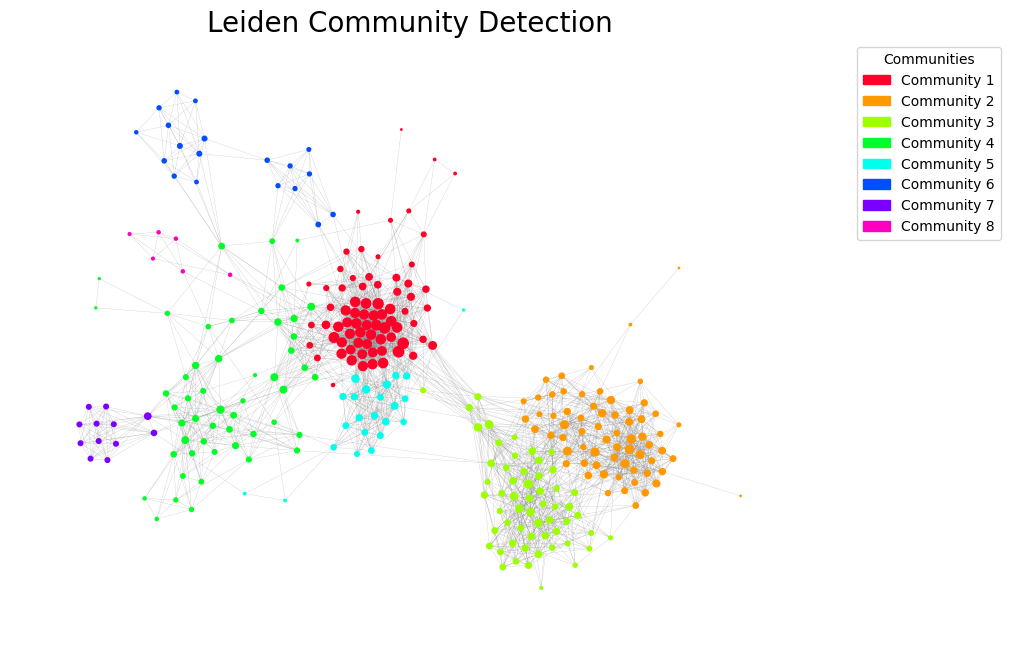

In [ ]:
BEST_SEED_LD = 7

# Convert NetworkX graph to igraph with Graph.from_networkx function that preserving original labels.
g_ig = ig.Graph.from_networkx(G)

# Leiden algorithm
partitions_leiden = la.find_partition(
    g_ig, la.ModularityVertexPartition, seed=BEST_SEED_LD
)

# Build communities in igraph indexing
communities_igraph_vids = [list(comm) for comm in partitions_leiden]

# Map igraph vertex IDs back to NetworkX labels
communities_leiden = [
    [g_ig.vs[v]["_nx_name"] for v in comm] for comm in communities_igraph_vids
]

# Count communities
print(
    "The number of communities found with the Leiden modularity algorithm is:",
    len(partitions_leiden),
)

# Color mapping
node_to_comm = {}
for comm_id, comm in enumerate(communities_leiden, start=1):
    for node in comm:
        node_to_comm[node] = comm_id

# Prepare colors for NetworkX
node_colors = [node_to_comm[n] for n in G.nodes()]

# Correct legend color mapping
cmap = plt.cm.gist_rainbow
norm = plt.Normalize(vmin=min(node_colors), vmax=max(node_colors))

# Build legend handles
unique_comms = sorted(set(node_colors))
legend_handles = [
    Patch(color=cmap(norm(comm)), label=f"Community {comm}") for comm in unique_comms
]

# Plot
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    pos=pos,
    node_color=node_colors,
    cmap=cmap,
    node_size=nodes_sizes,
    edge_color="grey",
    width=0.1,
)
plt.legend(
    handles=legend_handles,
    title="Communities",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)
plt.title("Leiden Community Detection", fontsize=20)
plt.show()

In [ ]:
print(
    "The count of detected communities are:\n", (pd.Series(node_colors)).value_counts()
)

The count of detected communities are:
 1    73
2    66
3    57
4    51
5    23
6    19
7    12
8     6
Name: count, dtype: int64


**Comparison of the algorithms based on modularity:**

In [ ]:
# Greedy
print(
    f"The Greedy algorithm:\n   - The number of communities detected is {len(communities_greedy)}."
)

modularity_greedy = nx.community.modularity(G, communities_greedy)
print(f"   - The modularity of the inferred partitions is {modularity_greedy:.4f}.")

# Louvain
print(
    f"\nThe Louvain algorithm:\n   - The number of communities detection is {len(communities_louvain)}."
)

modularity_louvain = nx.community.modularity(G, communities_louvain)
print(f"   - The modularity of the inferred partitions is {modularity_louvain:.4f}.")

# Leiden
print(
    f"\nThe Leiden algorithm:\n   - The number of communities detected is {len(partitions_leiden)}."
)

modularity_leiden = nx.community.modularity(G, communities_leiden)
print(f"   - The modularity of the inferred partitions is {modularity_leiden:.4f}.")

The Greedy algorithm:
   - The number of communities detected is 5.
   - The modularity of the inferred partitions is 0.5929.

The Louvain algorithm:
   - The number of communities detection is 8.
   - The modularity of the inferred partitions is 0.6399.

The Leiden algorithm:
   - The number of communities detected is 8.
   - The modularity of the inferred partitions is 0.6401.


The three algorithms obtained a high modularity value of around 0.6, suggesting a modular structure of the biological network. The main differences between them are:

- Greedy’s modularity, despite being high, is the lowest one among them all. Due to its classification process, it may underperform on networks with heterogeneous community sizes. This is, merging communities that should remain separate. It seems to be the case here since there are fewer communities detected (5) than the rest of the algorithms present.
- Louvain presents a higher modularity value which indicates a strong modular and structural coherent network. In total, there are 8 inferred partitions that, even though larger than the reference partitions, correspond to meaningful subclusters inside the references (notice two communities detected in red and green in the middle).
- Leiden’s resulting graph also shows 8 clusters similarly balanced, slightly more compact and coherent than Louvain. Moreover, it presents the highest modularity among the three algorithms. Despite the fact it produces more communities than the references, the extra subdivisions usually correspond to sub-modules within the biological reference groups which eases interpretation.

Considering the previous descriptions, the algorithm that produces the highest modularity while yielding a meaningful number of communities is the Leiden algorithm. Therefore, it is selected as the primary modularity-based community detection algorithm.

**Adjacency matrix: Leiden algorithm**

In the following graph, the ordering of rows and columns has been permuted to match the inferred communities. Diagonal colored blocks are within-community links, and off-diagonal blocks are between-community links. The matrix is shown symmetrically to aid the eye.

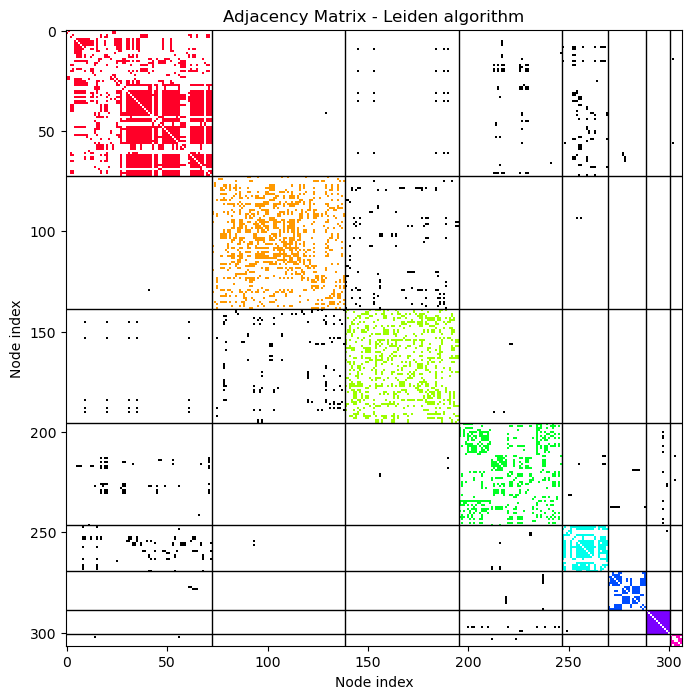

In [ ]:
# Mapping NetworkX nodes to graph-tool vertex indices
nx_nodes_sorted = list(G.nodes())
node_to_v = {node: i for i, node in enumerate(nx_nodes_sorted)}

# Build graph-tool graph
g = gt.Graph(directed=False)
g.add_vertex(len(nx_nodes_sorted))

for u, v in G.edges():
    g.add_edge(g.vertex(node_to_v[u]), g.vertex(node_to_v[v]))

# Map Leiden community labels
# node_to_comm comes from the Leiden algorithm section
mapped_labels_leiden = np.zeros(len(nx_nodes_sorted), dtype=int)
for node, vid in node_to_v.items():
    mapped_labels_leiden[vid] = node_to_comm[node]

# Sort adjacency matrix by community
A = gt.adjacency(g).toarray()
nodes_sorted = np.argsort(mapped_labels_leiden)
A_sorted = A[nodes_sorted][:, nodes_sorted]
labels_sorted = mapped_labels_leiden[nodes_sorted]

# Use the same colormap and normalize them
cmap = plt.cm.gist_rainbow
norm = plt.Normalize(vmin=min(node_colors), vmax=max(node_colors))

# Create RGB matrix
N = len(A_sorted)
color_matrix = np.ones((N, N, 3))

for i in range(len(A)):
    for j in range(len(A)):
        if A_sorted[i, j] == 1:
            if labels_sorted[i] == labels_sorted[j]:
                color_matrix[i, j] = cmap(norm(labels_sorted[i]))[:3]
            else:
                color_matrix[i, j] = (0, 0, 0)  # inter-community edges: black

# Plot
plt.figure(figsize=(8, 8))
plt.imshow(color_matrix, interpolation="none")
plt.title("Adjacency Matrix - Leiden algorithm")
plt.xlabel("Node index")
plt.ylabel("Node index")

# Draw community boundaries
unique_mods, counts = np.unique(labels_sorted, return_counts=True)
boundaries = np.cumsum(counts)
for b in boundaries[:-1]:
    plt.axhline(b - 0.5, color="black", linewidth=1.0)
    plt.axvline(b - 0.5, color="black", linewidth=1.0)

plt.show()

<a id='section212'></a>
#### **2.1.2 Infomap**

Infomap is an algorithm that uses information theory and random walks to detect communities. Instead of optimizing modularity, it identifies communities by minimizing the description length of a hypothetical random walker’s path through the network.  

Infomap represents the path of this random walk with a two-level codebook:  

- A short index for entering a community.  
- A shorter index for moving between nodes within that community.   

This allows the reuse of node indices across different communities.   

The algorithm searches for a partition of the network that results in the shortest total code length. Communities are therefore regions where the flow of information tends to remain confined.


In Infomap, setting a seed may change the number of detected communities. In our case, we run multiple seeds and pick the one that best matched the reference partitions.

In [26]:
# We have run for a range(1, 2001) and the majority are of 2 communities, some of 10 and very few of 9 (45, 54, ..., 1922, 1980)

seed_trial = range(1, 101)
n_modules = []

for s in seed_trial:
    im = Infomap(f"--seed {s}")

    for u, v in G.edges():
        im.add_link(u, v)
    im.run()
    modules = set(node.module_id for node in im.nodes)
    n_modules.append(len(modules))

  Infomap v2.8.0 starts at 2025-11-22 12:20:16
  -> Input network: 
  -> No file output!
  -> Configuration: seed = 1
  OpenMP 201511 detected with 28 threads...
  -> Ordinary network input, using the Map Equation for first order network flows
Calculating global network flow using flow model 'undirected'... 
  -> Using undirected links.
  => Sum node flow: 1, sum link flow: 1
Build internal network with 307 nodes and 2812 links...
  -> One-level codelength: 8.01615344

Trial 1/1 starting at 2025-11-22 12:20:16
Two-level compression: 19% 0.52% 
Partitioned to codelength 0.23611644 + 6.25123185 = 6.487348288 in 10 modules.
Super-level compression: to codelength 6.487348288 in 10 top modules.

Recursive sub-structure compression: 2.55723637% 0% . Found 3 levels with codelength 6.321451459

=> Trial 1/1 finished in 0.007961707s with codelength 6.32145146


Summary after 1 trial
Best end modular solution in 3 levels:
Per level number of modules:         [         10,           5,           

In [27]:
for i in range(len(seed_trial)):
    if n_modules[i] <= 11:
        print(f"Seed {seed_trial[i]}: {n_modules[i]} communities")
    else:
        continue

Seed 1: 10 communities
Seed 2: 2 communities
Seed 3: 2 communities
Seed 4: 2 communities
Seed 5: 2 communities
Seed 6: 2 communities
Seed 7: 2 communities
Seed 8: 2 communities
Seed 9: 10 communities
Seed 10: 2 communities
Seed 11: 2 communities
Seed 12: 2 communities
Seed 13: 2 communities
Seed 14: 11 communities
Seed 15: 2 communities
Seed 16: 11 communities
Seed 17: 2 communities
Seed 18: 2 communities
Seed 19: 2 communities
Seed 20: 2 communities
Seed 21: 11 communities
Seed 22: 2 communities
Seed 23: 2 communities
Seed 24: 2 communities
Seed 25: 10 communities
Seed 26: 2 communities
Seed 27: 2 communities
Seed 28: 2 communities
Seed 29: 10 communities
Seed 30: 2 communities
Seed 31: 2 communities
Seed 32: 2 communities
Seed 33: 2 communities
Seed 34: 2 communities
Seed 35: 2 communities
Seed 36: 2 communities
Seed 37: 2 communities
Seed 38: 2 communities
Seed 39: 2 communities
Seed 40: 2 communities
Seed 41: 2 communities
Seed 42: 2 communities
Seed 43: 2 communities
Seed 44: 2 co

As can be seen from the output above, the first seed that resembles the closest to the reference partitions of 4 and 6 communities is seed 2 with 2 communities.

In [28]:
BEST_SEED_IM = 2

# Run Infomap community detection
im = Infomap(f"--seed {BEST_SEED_IM}")
for u, v in G.edges():
    im.add_link(u, v)

im.run()

# Extract communities and create module mapping
communities_infomap = {node.node_id: node.module_id for node in im.nodes}

. Found 3 levels with codelength 6.338599143

=> Trial 1/1 finished in 0.004158477s with codelength 6.33859914


Summary after 1 trial
Best end modular solution in 3 levels:
Per level number of modules:         [          2,          17,           0] (sum: 19)
Per level number of leaf nodes:      [          0,           0,         307] (sum: 307)
Per level average child degree:      [          2,         8.5,     18.0588] (average: 17.4618)
Per level codelength for modules:    [0.011379801, 0.609754704, 0.000000000] (sum: 0.621134505)
Per level codelength for leaf nodes: [0.000000000, 0.000000000, 5.717464638] (sum: 5.717464638)
Per level codelength total:          [0.011379801, 0.609754704, 5.717464638] (sum: 6.338599143)

  Infomap ends at 2025-11-22 12:20:17
  (Elapsed time: 0.0049566s)
  Infomap v2.8.0 starts at 2025-11-22 12:20:17
  -> Input network: 
  -> No file output!
  -> Configuration: seed = 2
  OpenMP 201511 detected with 28 threads...
  -> Ordinary network input, using th

Number of communities detected by Infomap: 2


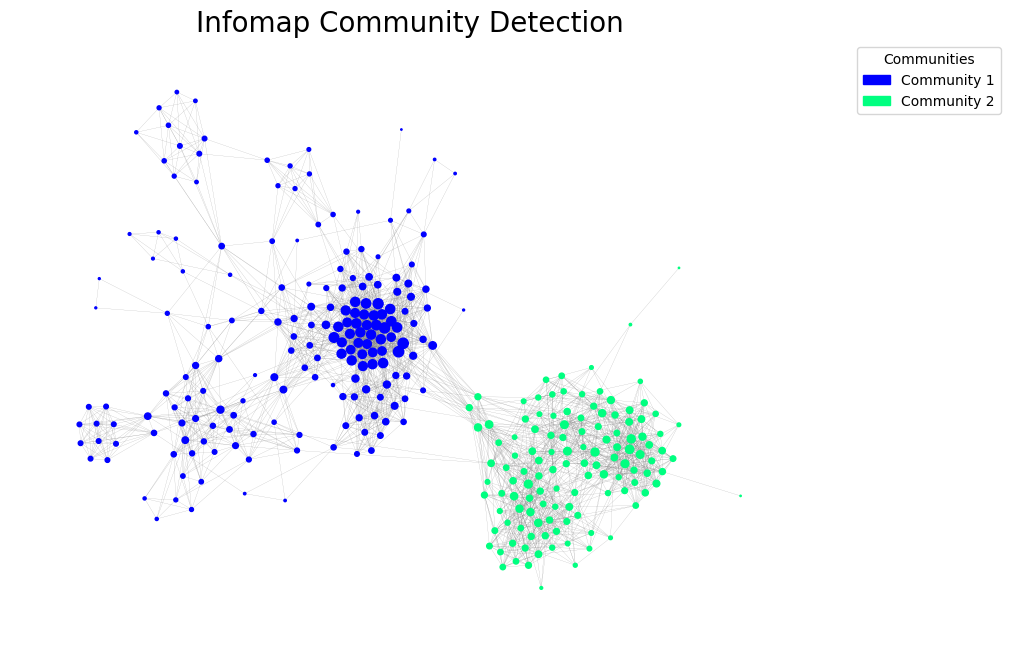

In [ ]:
# Map module IDs to consecutive 0..k-1
unique_modules = sorted(set(communities_infomap.values()))
color_map = {mod: i for i, mod in enumerate(unique_modules)}

node_colors = [color_map[communities_infomap[n]] for n in G.nodes()]

# Number of communities
num_communities_infomap = len(unique_modules)
print("Number of communities detected by Infomap:", num_communities_infomap)

# Use the colormap and normalize
cmap = plt.cm.winter
norm = plt.Normalize(vmin=0, vmax=num_communities_infomap - 1)

# Building legend patches
legend_handles = [
    Patch(color=cmap(norm(color_map[mod])), label=f"Community {i}")
    for i, mod in enumerate(unique_modules, start=1)
]

# Plot with HSV colormap
plt.figure(figsize=(8, 6))
nx.draw(
    G,
    pos=pos,
    node_color=node_colors,
    cmap=cmap,
    node_size=nodes_sizes,
    edge_color="grey",
    width=0.1,
    linewidths=1,
)
plt.legend(
    handles=legend_handles,
    title="Communities",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)
plt.title("Infomap Community Detection", fontsize=20)
plt.show()

In [ ]:
print(
    "The count of detected communities are:\n",
    (pd.Series(communities_infomap)).value_counts(),
)

The count of detected communities are:
 1    185
2    122
Name: count, dtype: int64


**Adjacency matrix: Infomap algorithm**

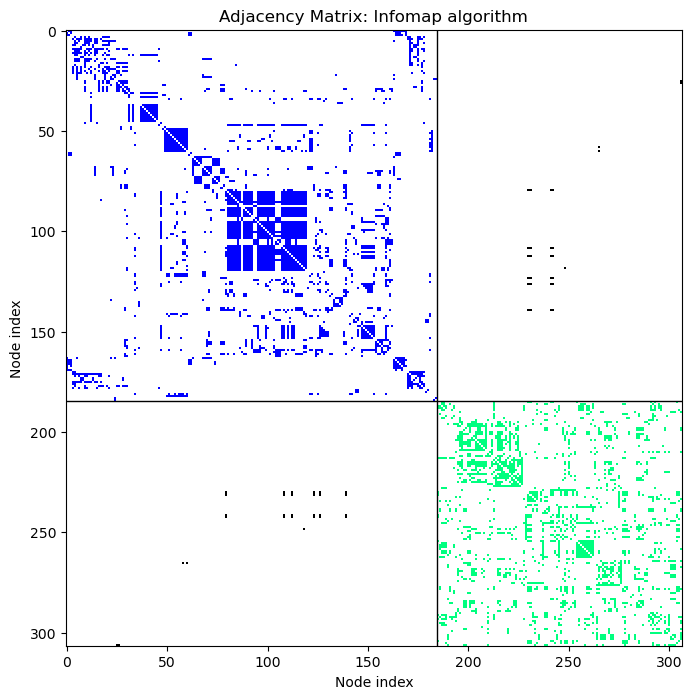

In [ ]:
# Renumber modules to consecutive 0..k-1
unique_modules = sorted(set(communities_infomap.values()))
module_map = {m: i for i, m in enumerate(unique_modules)}

# Create label list aligned with NetworkX node ordering
mapped_labels_infomap = np.array(
    [module_map[communities_infomap[n]] for n in G.nodes()]
)

# Number of communities detected by Infomap
num_communities_infomap = len(unique_modules)

# Convert to adjacency matrix
A = gt.adjacency(g).toarray()

# Sort nodes by Infomap community
nodes_sorted = np.argsort(mapped_labels_infomap)
A_sorted = A[nodes_sorted][:, nodes_sorted]
labels_sorted = mapped_labels_infomap[nodes_sorted]

# Modern Matplotlib colormap (no deprecations)
cmap = plt.colormaps["winter"].resampled(num_communities_infomap)

# Prepare RGB matrix (white background = no edge)
color_matrix = np.ones((len(A_sorted), len(A_sorted), 3))

# Fill colors
for i in range(len(A_sorted)):
    for j in range(len(A_sorted)):
        if A_sorted[i, j] == 1:
            if labels_sorted[i] == labels_sorted[j]:
                rgba = cmap(labels_sorted[i])  # RGBA
                color_matrix[i, j] = rgba[:3]  # RGB only
            else:
                color_matrix[i, j] = (0, 0, 0)  # Black for different modules

plt.figure(figsize=(8, 8))
plt.imshow(color_matrix, interpolation="none")
plt.title("Adjacency Matrix: Infomap algorithm")
plt.xlabel("Node index")
plt.ylabel("Node index")

unique_mods, counts = np.unique(labels_sorted, return_counts=True)
boundaries = np.cumsum(counts)

for b in boundaries[:-1]:
    plt.axhline(b - 0.5, color="black", linewidth=1.0)
    plt.axvline(b - 0.5, color="black", linewidth=1.0)

plt.show()

<a id='section213'></a>
#### **2.1.3 Degree corrected stochastic block model (DC-SBM)**  

The Degree-Corrected Stochastic Block Model (DC-SBM) is an extension of the standard Stochastic Block Model (SBM). While the SBM assumes that all nodes within the same community must have similar expected degrees, the DC-SBM accounts for differences in node degrees by introducing a degree parameter for each node to model degree heterogeneity. This allows the model to correctly identify communities even in real-world networks where some nodes are highly connected hubs while others are sparsely connected.

In [ ]:
# We have run a seed_trial of range(1, 2001) and the only seed with nº of detected communities smaller or equal to 10 appears in the range below.

# List of seeds to test
seed_trial = range(900, 1001)
n_communities_list = []
best_seed = None
max_comms = 0
min_comms = 60

# Store the best state for plotting later
best_state = None

for SEED in seed_trial:
    # Set seed for graph-tool
    gt.seed_rng(SEED)

    # Convert NetworkX graph to graph-tool
    g = gt.Graph(directed=False)
    g.add_vertex(len(G.nodes()))

    # Add edges
    for u, v in G.edges():
        g.add_edge(g.vertex(u), g.vertex(v))

    # Degree-corrected SBM
    state = gt.minimize_blockmodel_dl(g)

    # Extract labels
    labels = state.get_blocks()
    raw_labels = [int(labels[v]) for v in g.vertices()]
    unique_raw = sorted(set(raw_labels))
    num_comms = len(unique_raw)
    n_communities_list.append(num_comms)

    if num_comms <= 10:
        print(f"Seed {SEED}: {num_comms} communities")

    # Check the largest communities detected by a seed (at times, the best has max communities)
    if num_comms > max_comms:
        max_comms = num_comms
        largest_seed = SEED
        largest_state = state

    if num_comms < min_comms:
        min_comms = num_comms
        smallest_seed = SEED
        smallest_state = state

print(f"\nSeed with most communities: {largest_seed} with {max_comms} communities")
print(f"Seed with least communities: {smallest_seed} with {min_comms} communities")

Seed 936: 9 communities

Seed with most communities: 960 with 60 communities
Seed with least communities: 936 with 9 communities


Over seed 1 to 2000, the algorithm detects the sizes of the maximum and minimum communities:

- Seed with most communities: 574 with 91 communities
- Seed with least communities: 936 with 9 communities

Number of communities detected by DC-SBM: 9


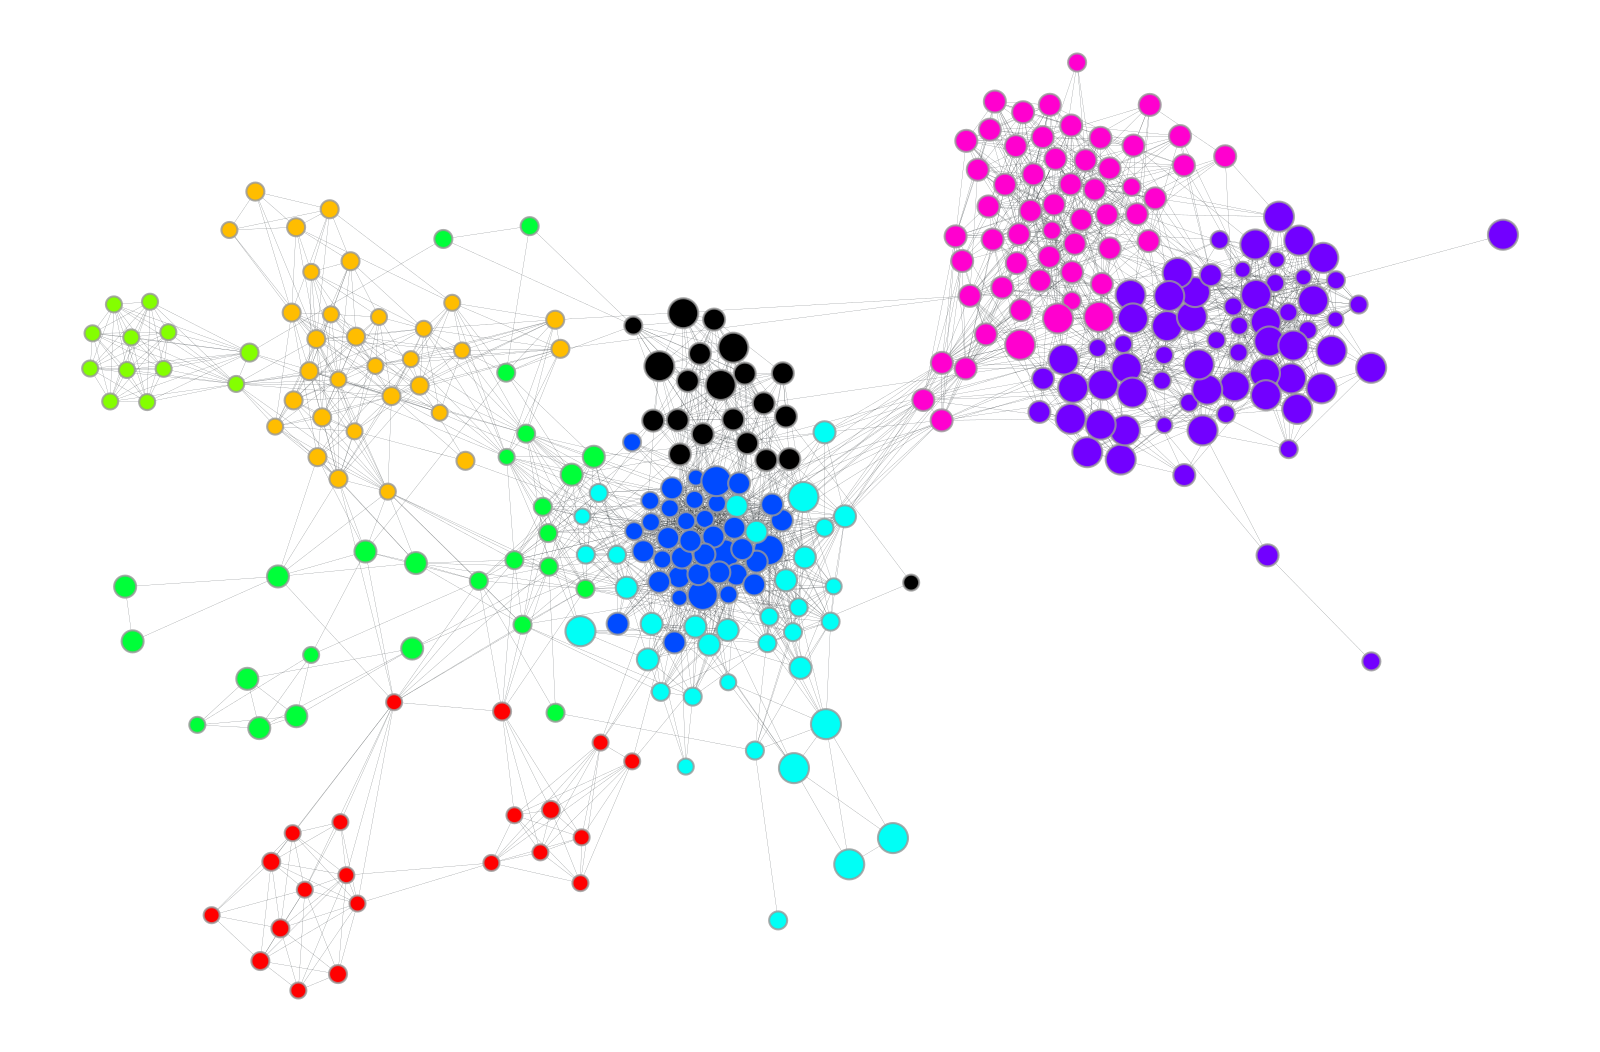

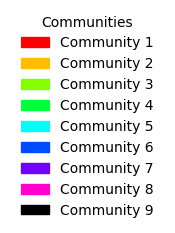

In [ ]:
BEST_SEED_SBM = 936

# Set seed for graph-tool
gt.seed_rng(BEST_SEED_SBM)

# Convert NetworkX graph to graph-tool
g = gt.Graph(directed=False)
g.add_vertex(len(G.nodes()))

# Add edges
for u, v in G.edges():
    g.add_edge(g.vertex(u), g.vertex(v))

# Degree-corrected SBM (default)
state = gt.minimize_blockmodel_dl(g)

# Extract labels (node with its community)
labels = state.get_blocks()
raw_labels = [int(labels[v]) for v in g.vertices()]
unique_raw = sorted(set(raw_labels))
num_communities_dcsbm = len(unique_raw)

print("Number of communities detected by DC-SBM:", num_communities_dcsbm)

# Convert NetworkX pos dictionary into graph-tool property
pos_gt = g.new_vertex_property("vector<double>")
for v in g.vertices():
    pos_gt[v] = list(map(float, pos[int(v)]))

# Remap labels to 1 to k
label_map = {lab: i for i, lab in enumerate(unique_raw)}
mapped_labels = [label_map[lab] for lab in raw_labels]

# Generate colors: Resample colormap to N colors for all except the last community
cmap = plt.cm.hsv
colors = cmap(np.linspace(0, 1, num_communities_dcsbm))
colors[-1] = [0, 0, 0, 1]  # last community in black

# Assign the vertex colors compatible to graph-draw
color_prop = g.new_vertex_property("vector<float>")
for v, lbl in zip(g.vertices(), mapped_labels):
    rgba = colors[lbl].tolist()  # list of 4 floats
    color_prop[v] = rgba

# Create graph-tool vertex-size property
size_prop = g.new_vertex_property("double")
for v in g.vertices():
    size_prop[v] = nodes_sizes[round(int(v) / max(nodes_sizes))]

# Legend
legend_handles = [
    Patch(color=colors[i], label=f"Community {i + 1}")
    for i in range(num_communities_dcsbm)
]

# Plot: "Degree-corrected SBM Community Detection"
pos = gt.graph_draw(
    g,
    pos=pos_gt,
    vertex_fill_color=color_prop,
    vertex_size=size_prop,
    edge_pen_width=0.1,
    output_size=(800, 800),
)

# Plot legend separately
plt.figure(figsize=(2, 2))
plt.legend(handles=legend_handles, title="Communities", loc="center", frameon=False)
plt.axis("off")
plt.show()

In [ ]:
mapped_labes_correct = [x + 1 for x in mapped_labels]
print(
    "The count of detected communities are:\n",
    pd.Series(mapped_labes_correct).value_counts(),
)

The count of detected communities are:
 7    66
8    56
6    38
5    36
2    31
4    26
1    21
9    21
3    12
Name: count, dtype: int64


**Adjacency matrix: Degree Corrected Stochastic Block Model algorithm**

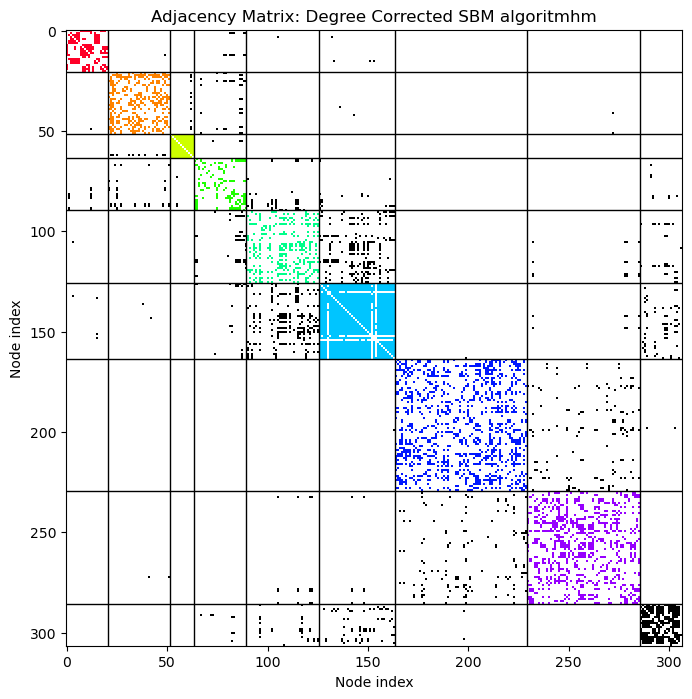

In [35]:
# Extract adjacency matrix (0/1)
A = gt.adjacency(g).toarray()

# Sort nodes by community
nodes_sorted = np.argsort(mapped_labels)
A_sorted = A[nodes_sorted][:, nodes_sorted]
labels_sorted = np.array(mapped_labels)[nodes_sorted]

# Same colors as in the network graph (gist_rainbow and the last community in black)
cmap = plt.cm.gist_rainbow
colors = cmap(np.linspace(0, 1, num_communities_dcsbm))
colors[-1] = [0, 0, 0, 1]

# Build the RGB matrix
N = len(A_sorted)
color_matrix = np.ones((N, N, 3))  # white background

# Fill
for i in range(N):
    for j in range(N):
        if A_sorted[i, j] == 1:
            if labels_sorted[i] == labels_sorted[j]:
                # Same community → get the same RGB colors as graph nodes
                r, g_, b, _ = colors[labels_sorted[i]]
                color_matrix[i, j] = (r, g_, b)
            else:
                # Black for inter-community edge
                color_matrix[i, j] = (0, 0, 0)

# Plot the community-colored adjacency matrix
plt.figure(figsize=(8, 8))
plt.imshow(color_matrix, interpolation="none")
plt.title("Adjacency Matrix: Degree Corrected SBM algoritmhm")
plt.xlabel("Node index")
plt.ylabel("Node index")

# Draw boundaries between communities
unique_mods, counts = np.unique(labels_sorted, return_counts=True)
boundaries = np.cumsum(counts)

for b in boundaries[:-1]:
    plt.axhline(b - 0.5, color="black", linewidth=1.0)
    plt.axvline(b - 0.5, color="black", linewidth=1.0)

plt.show()

<a id='section22'></a>
### **2.2 Comparison of algorithms' performance**

In this section, we compare the results between Leiden algorithm, Infomap and degree-corrected SBM to the reference partitions.

**Function that plots the distribution of a given algorithm's inferred communities**

In [ ]:
def inferred_communities(merge_df, parameter, name_algorithm):
    """
    Plots the inferred communities from a given community detection algorithm
    against the reference partitions based on a parameter.
    """

    # Sort list of classes based on the selected parameter
    list_classes = merge_df[parameter].unique()
    list_classes.sort()

    # Sort list of communities
    list_communities = merge_df["community"].unique()
    list_communities.sort()

    # Number of reference classes:
    number_classes = len(list_classes)
    # Have as many colors as the number of classes
    colors = plt.cm.gist_rainbow(np.linspace(0, 1, number_classes))

    # Dictionary that contains the color assigned to each class
    color_class = {}
    label_class = {}
    count_class = 0
    for class_ in list_classes:
        color_class[class_] = colors[count_class]
        # For visualization purposes in the legend of the figure
        label_class[class_] = 0
        count_class = count_class + 1

    # We count the nodes sharing class and community
    statistics = (
        merge_df.groupby(["community", parameter])["index"].count().reset_index()
    )

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))

    for community in list_communities:
        # Keep only the classes in each community
        statistics_communities = statistics[statistics["community"] == community]
        bottom_ref = 0  # Set the bottom coordinate of the bar
        # Number of individuals in this community and class
        node_values = statistics_communities["index"].values
        # Class of the individuals (to fix color)
        class_values = statistics_communities[parameter].values

        for row in range(len(statistics_communities)):
            if label_class[class_values[row]] == 0:
                # We just want the label to appear once
                ax.bar(
                    community,
                    node_values[row],
                    color=color_class[class_values[row]],
                    bottom=bottom_ref,
                    label=class_values[row],
                )
                label_class[class_values[row]] = 1
            else:
                # We do not put any label if the class is already in the figure
                ax.bar(
                    community,
                    node_values[row],
                    color=color_class[class_values[row]],
                    bottom=bottom_ref,
                )
            # Keep stacking class on top of the previous one within the same community
            bottom_ref = bottom_ref + node_values[row]

    ax.set_xlabel("Inferred communities")
    ax.set_ylabel(f"{parameter} composition of communities")
    ax.set_title(
        f"Correspondence of network communities to existing classifications of {parameter}\nfrom the {name_algorithm} algorithm"
    )

    # Sort the labels in the legend
    handles, labels = ax.get_legend_handles_labels()
    labels, handles = zip(*sorted(zip(labels, handles), key=lambda t: t[0]))
    ax.legend(handles, labels, fontsize=11, frameon=False)

    # Force x-axis to show only the actual communities as integers
    ax.set_xticks(list_communities)
    ax.set_xticklabels(list_communities)

**Leiden algorithm:**

In [ ]:
# Convert Leiden communities to DataFrame
list_nodes_leiden = [node for comm in communities_leiden for node in comm]
list_communities_leiden = [
    comm_id for comm_id, comm in enumerate(communities_leiden, start=1) for node in comm
]

df_community_leiden_unord = pd.DataFrame(
    zip(list_nodes_leiden, list_communities_leiden), columns=["index", "community"]
)

df_community_leiden = df_community_leiden_unord.sort_values(
    by=["community", "index"], ascending=[True, True]
).reset_index(drop=True)

df_community_leiden["index"] = df_community_leiden["index"].astype(int)

print(df_community_leiden.head())

   index  community
0     68          1
1     76          1
2     78          1
3     79          1
4     81          1


In [ ]:
merge_df_cys_leiden = pd.merge(
    df_community_leiden, metadata_cys, on="index"
).sort_values("index")
merge_df_ups_leiden = pd.merge(
    df_community_leiden, metadata_ups, on="index"
).sort_values("index")

print(merge_df_cys_leiden.head(), "\n\n", merge_df_ups_leiden.head())

     index  community  CysPoLV
270      0          6        3
196      1          4        3
197      2          4        1
198      3          4        1
199      4          4        1 

      index  community  UPS
270      0          6    1
196      1          4    1
197      2          4    1
198      3          4    1
199      4          4    1


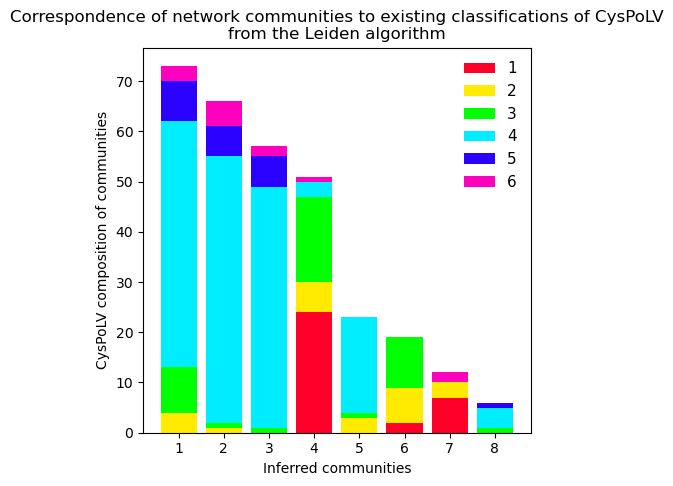

In [39]:
inferred_communities(merge_df_cys_leiden, "CysPoLV", "Leiden")

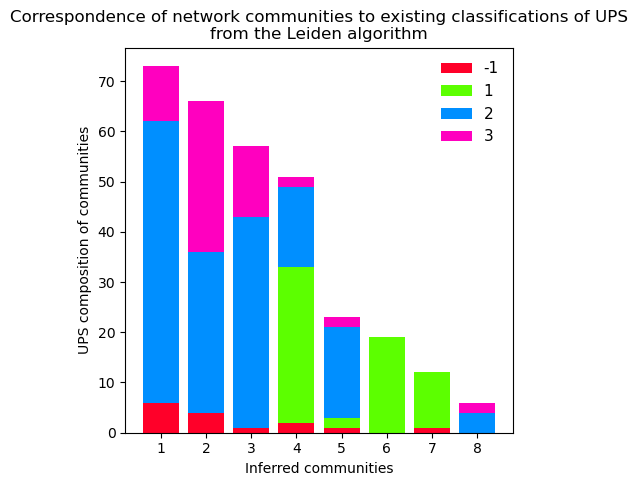

In [40]:
inferred_communities(merge_df_ups_leiden, "UPS", "Leiden")

**Infomap:**

In [ ]:
# Convert Infomap dict to DataFrame
list_nodes_infomap = list(communities_infomap.keys())
list_communities_infomap = list(communities_infomap.values())

df_community_infomap_unord = pd.DataFrame(
    zip(list_nodes_infomap, list_communities_infomap), columns=["index", "community"]
)

df_community_infomap = df_community_infomap_unord.sort_values(
    by=["community", "index"], ascending=[True, True]
).reset_index(drop=True)

df_community_infomap["index"] = df_community_infomap["index"].astype(int)

print(df_community_infomap.head())

   index  community
0      0          1
1      1          1
2      2          1
3      3          1
4      4          1


In [42]:
merge_df_cys_infomap = pd.merge(
    df_community_infomap, metadata_cys, on="index"
).sort_values("index")

merge_df_ups_infomap = pd.merge(
    df_community_infomap, metadata_ups, on="index"
).sort_values("index")

print(merge_df_cys_infomap.head(), "\n\n", merge_df_ups_infomap.head())

   index  community  CysPoLV
0      0          1        3
1      1          1        3
2      2          1        1
3      3          1        1
4      4          1        1 

    index  community  UPS
0      0          1    1
1      1          1    1
2      2          1    1
3      3          1    1
4      4          1    1


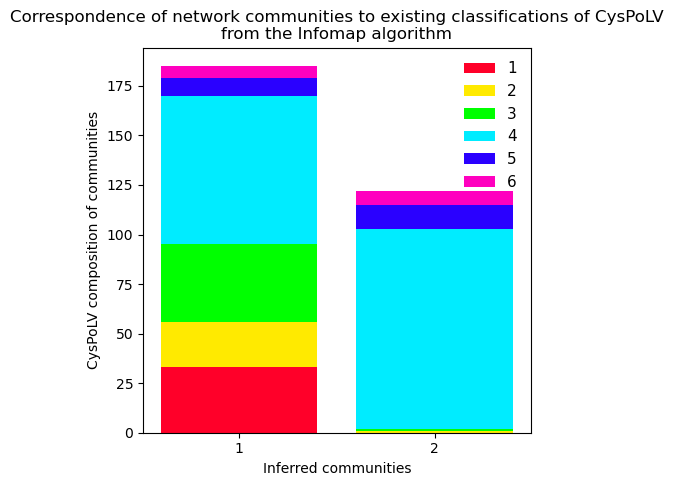

In [43]:
inferred_communities(merge_df_cys_infomap, "CysPoLV", "Infomap")

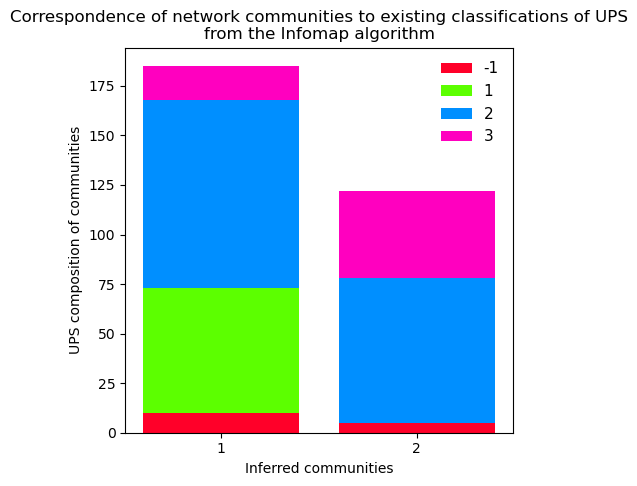

In [44]:
inferred_communities(merge_df_ups_infomap, "UPS", "Infomap")

**Degree corrected Stochastic Block Model:**

In [ ]:
# Convert DC-SBM dict to DataFrame
list_nodes_dcsbm = list(range(len(mapped_labels)))
list_communities_dcsbm = [comm_id + 1 for comm_id in mapped_labels]

df_community_dcsbm_unord = pd.DataFrame(
    zip(list_nodes_dcsbm, list_communities_dcsbm), columns=["index", "community"]
)

df_community_dcsbm = df_community_dcsbm_unord.sort_values(
    by=["community", "index"], ascending=[True, True]
).reset_index(drop=True)

df_community_dcsbm["index"] = df_community_dcsbm["index"].astype(int)

print(df_community_dcsbm.head())

   index  community
0      0          1
1     15          1
2     17          1
3     18          1
4     19          1


In [ ]:
merge_df_cys_dcsbm = pd.merge(df_community_dcsbm, metadata_cys, on="index").sort_values(
    "index"
)

merge_df_ups_dcsbm = pd.merge(df_community_dcsbm, metadata_ups, on="index").sort_values(
    "index"
)

print(merge_df_cys_dcsbm.head(), "\n\n")
print(merge_df_ups_dcsbm.head())

    index  community  CysPoLV
0       0          1        3
21      1          2        3
22      2          2        1
23      3          2        1
24      4          2        1 


    index  community  UPS
0       0          1    1
21      1          2    1
22      2          2    1
23      3          2    1
24      4          2    1


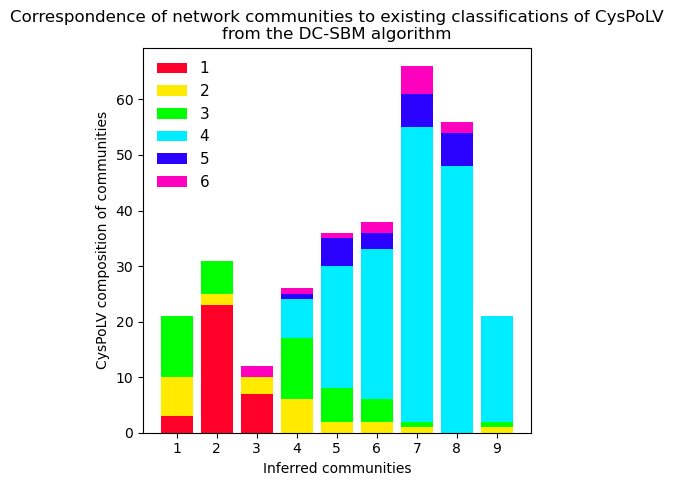

In [47]:
inferred_communities(merge_df_cys_dcsbm, "CysPoLV", "DC-SBM")

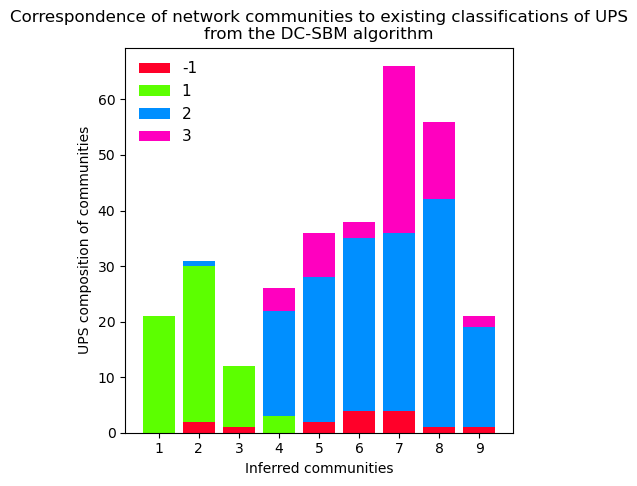

In [48]:
inferred_communities(merge_df_ups_dcsbm, "UPS", "DC-SBM")

---
<a id='section3'></a>
## **3. Analysis of detected comunities**

<a id='section31'></a>
### **3.1 Leiden algorithm**

In [ ]:
# Fraction of nodes per inferred community that belong to each reference class
frac_cys_ld = (
    merge_df_cys_leiden.groupby(["community", "CysPoLV"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print("\nFraction of CysPoLV classes per Leiden community:\n\n", frac_cys_ld)


Fraction of CysPoLV classes per Leiden community:

 community  CysPoLV
1          2          0.054795
           3          0.123288
           4          0.671233
           5          0.109589
           6          0.041096
2          2          0.015152
           3          0.015152
           4          0.803030
           5          0.090909
           6          0.075758
3          3          0.017544
           4          0.842105
           5          0.105263
           6          0.035088
4          1          0.470588
           2          0.117647
           3          0.333333
           4          0.058824
           6          0.019608
5          2          0.130435
           3          0.043478
           4          0.826087
6          1          0.105263
           2          0.368421
           3          0.526316
7          1          0.583333
           2          0.250000
           6          0.166667
8          3          0.166667
           4          0.66666

In [ ]:
# Fraction of nodes per inferred community that belong to each UPS class
frac_ups_ld = (
    merge_df_ups_leiden.groupby(["community", "UPS"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print("\nFraction of UPS classes per Leiden community:\n\n", frac_ups_ld)


Fraction of UPS classes per Leiden community:

 community  UPS
1          -1     0.082192
            2     0.767123
            3     0.150685
2          -1     0.060606
            2     0.484848
            3     0.454545
3          -1     0.017544
            2     0.736842
            3     0.245614
4          -1     0.039216
            1     0.607843
            2     0.313725
            3     0.039216
5          -1     0.043478
            1     0.086957
            2     0.782609
            3     0.086957
6           1     1.000000
7          -1     0.083333
            1     0.916667
8           2     0.666667
            3     0.333333
dtype: float64


In [51]:
# Community statistics
community_stats_leiden = {}

for c in set(node_to_comm.values()):
    nodes_c = [n for n, com in node_to_comm.items() if com == c]
    subgraph = G.subgraph(nodes_c)

    community_stats_leiden[c] = {
        "size": len(nodes_c),
        "avg_degree": np.mean([d for n, d in subgraph.degree()]),
        "density": nx.density(subgraph),
        "num_edges": subgraph.number_of_edges(),
        "hub_nodes": sorted(subgraph.degree(), key=lambda x: x[1], reverse=True)[:5],
    }

community_stats_leiden

{1: {'size': 73,
  'avg_degree': np.float64(26.301369863013697),
  'density': 0.365296803652968,
  'num_edges': 960,
  'hub_nodes': [(262, 50), (119, 50), (256, 47), (272, 47), (278, 44)]},
 2: {'size': 66,
  'avg_degree': np.float64(16.151515151515152),
  'density': 0.24848484848484848,
  'num_edges': 533,
  'hub_nodes': [(155, 35), (163, 34), (137, 30), (142, 28), (149, 28)]},
 3: {'size': 57,
  'avg_degree': np.float64(14.210526315789474),
  'density': 0.25375939849624063,
  'num_edges': 405,
  'hub_nodes': [(206, 27), (240, 27), (215, 23), (216, 23), (217, 23)]},
 4: {'size': 51,
  'avg_degree': np.float64(10.823529411764707),
  'density': 0.2164705882352941,
  'num_edges': 276,
  'hub_nodes': [(24, 24), (2, 21), (56, 18), (3, 17), (63, 17)]},
 5: {'size': 23,
  'avg_degree': np.float64(11.826086956521738),
  'density': 0.5375494071146245,
  'num_edges': 136,
  'hub_nodes': [(302, 18), (180, 18), (299, 16), (303, 16), (306, 16)]},
 6: {'size': 19,
  'avg_degree': np.float64(7.47368

In [ ]:
# Betweenness centrality of nodes within each community
betweenness_cent = nx.betweenness_centrality(G)

for c in set(node_to_comm.values()):
    nodes_c = [n for n, com in node_to_comm.items() if com == c]
    top_bet = sorted(
        [(n, betweenness_cent[n]) for n in nodes_c], key=lambda x: x[1], reverse=True
    )[:5]
    print(f"Highest betweenness nodes from Community {c}:\n{top_bet}")

Highest betweenness nodes from Community 1:
[(293, 0.09987468860361176), (269, 0.09345474858576974), (256, 0.04808050128558992), (272, 0.04808050128558992), (96, 0.026524924422605647)]
Highest betweenness nodes from Community 2:
[(178, 0.10490693115975404), (190, 0.06594983134611695), (164, 0.02087915152011637), (183, 0.01783918089958115), (88, 0.011804873908628846)]
Highest betweenness nodes from Community 3:
[(204, 0.09055759228808992), (288, 0.07714708633003137), (289, 0.06483596726945916), (290, 0.040074843515553786), (291, 0.040074843515553786)]
Highest betweenness nodes from Community 4:
[(36, 0.0700087553902844), (111, 0.061197123012596534), (77, 0.045967776453212546), (6, 0.043765247556100645), (7, 0.043765247556100645)]
Highest betweenness nodes from Community 5:
[(303, 0.03825479660419687), (306, 0.03197673464891421), (14, 0.01313526175836855), (304, 0.008356867363396803), (295, 0.007851804176851827)]
Highest betweenness nodes from Community 6:
[(43, 0.021748132954455074), (4

The results above show how some communities (1-4) are less dense than others but still have large connectivity due to their high number of edges. This suggests that these communities have bridge nodes (nodes with high betweenness centrality) that connect different sub-regions within the community. In contrast, communities 5-8 are more dense but have fewer number of edges. Additionally, the low betweenness scores indicate that no single node controls the flow.

<a id='section32'></a>
### **3.2 Infomap**

In [ ]:
# Fraction of CysPoLV classes per Infomap community
frac_cys_infomap_df = (
    merge_df_cys_infomap.groupby(["community", "CysPoLV"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print("\nInfomap - CysPoLV fractions per community:\n\n", frac_cys_infomap_df)


Infomap - CysPoLV fractions per community:

 community  CysPoLV
1          1          0.178378
           2          0.124324
           3          0.210811
           4          0.405405
           5          0.048649
           6          0.032432
2          2          0.008197
           3          0.008197
           4          0.827869
           5          0.098361
           6          0.057377
dtype: float64


In [ ]:
# Fraction of UPS classes per Infomap community
frac_ups_infomap = (
    merge_df_ups_infomap.groupby(["community", "UPS"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print("\nInfomap - UPS fractions per community:\n\n", frac_ups_infomap)


Infomap - UPS fractions per community:

 community  UPS
1          -1     0.054054
            1     0.340541
            2     0.513514
            3     0.091892
2          -1     0.040984
            2     0.598361
            3     0.360656
dtype: float64


In [55]:
# Community statistics
community_stats_infomap = {}

for c in set(communities_infomap.values()):
    nodes_c = [n for n, com in communities_infomap.items() if com == c]
    subgraph = G.subgraph(nodes_c)

    community_stats_infomap[c] = {
        "size": len(nodes_c),
        "avg_degree": np.mean([d for n, d in subgraph.degree()]),
        "density": nx.density(subgraph),
        "num_edges": subgraph.number_of_edges(),
        "hub_nodes": sorted(subgraph.degree(), key=lambda x: x[1], reverse=True)[:5],
    }

community_stats_infomap

{1: {'size': 185,
  'avg_degree': np.float64(18.572972972972973),
  'density': 0.1009400705052879,
  'num_edges': 1718,
  'hub_nodes': [(262, 53), (119, 51), (256, 51), (272, 51), (102, 48)]},
 2: {'size': 122,
  'avg_degree': np.float64(17.459016393442624),
  'density': 0.144289391681344,
  'num_edges': 1065,
  'hub_nodes': [(155, 36), (163, 34), (149, 33), (206, 32), (142, 31)]}}

In [ ]:
# Betweenness centrality of nodes within each community
betweenness_cent = nx.betweenness_centrality(G)

for c in set(communities_infomap.values()):
    nodes_c = [n for n, com in communities_infomap.items() if com == c]
    top_bet = sorted(
        [(n, betweenness_cent[n]) for n in nodes_c], key=lambda x: x[1], reverse=True
    )[:5]
    print(f"Highest betweenness nodes from Community {c}:\n{top_bet}")

Highest betweenness nodes from Community 1:
[(293, 0.09987468860361176), (269, 0.09345474858576974), (36, 0.0700087553902844), (111, 0.061197123012596534), (256, 0.04808050128558992)]
Highest betweenness nodes from Community 2:
[(178, 0.10490693115975404), (204, 0.09055759228808992), (288, 0.07714708633003137), (190, 0.06594983134611695), (289, 0.06483596726945916)]


The infomap algorithm grouped the network into two large communities. Both communities have relatively low density, indicating that they contain many nodes but with sparse internal connectivity. Additionally, we can see that nodes 293 and 178 have the highest betweenness, meaning that they act as major bridges across different regions of the network.

<a id='section33'></a>
### **3.3 Degree corrected stochastic block model**

In [ ]:
# Fraction of CysPoLV classes per Degree-corrected SBM community
frac_cys_dc_sbm = (
    merge_df_cys_dcsbm.groupby(["community", "CysPoLV"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print(
    "\nFraction of CysPoLV classes per Degree-corrected SBM community:\n\n",
    frac_cys_dc_sbm,
)


Fraction of CysPoLV classes per Degree-corrected SBM community:

 community  CysPoLV
1          1          0.142857
           2          0.333333
           3          0.523810
2          1          0.741935
           2          0.064516
           3          0.193548
3          1          0.583333
           2          0.250000
           6          0.166667
4          2          0.230769
           3          0.423077
           4          0.269231
           5          0.038462
           6          0.038462
5          2          0.055556
           3          0.166667
           4          0.611111
           5          0.138889
           6          0.027778
6          2          0.052632
           3          0.105263
           4          0.710526
           5          0.078947
           6          0.052632
7          2          0.015152
           3          0.015152
           4          0.803030
           5          0.090909
           6          0.075758
8          4   

In [ ]:
# Fraction of UPS classes per Degree-corrected SBM community
frac_ups_dc_sbm = (
    merge_df_ups_dcsbm.groupby(["community", "UPS"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .droplevel(0)
)

print(
    "\nFraction of UPS classes per Degree-corrected SBM community:\n\n", frac_ups_dc_sbm
)


Fraction of UPS classes per Degree-corrected SBM community:

 community  UPS
1           1     1.000000
2          -1     0.064516
            1     0.903226
            2     0.032258
3          -1     0.083333
            1     0.916667
4           1     0.115385
            2     0.730769
            3     0.153846
5          -1     0.055556
            2     0.722222
            3     0.222222
6          -1     0.105263
            2     0.815789
            3     0.078947
7          -1     0.060606
            2     0.484848
            3     0.454545
8          -1     0.017857
            2     0.732143
            3     0.250000
9          -1     0.047619
            2     0.857143
            3     0.095238
dtype: float64


In [ ]:
# Community statistics
community_stats_dcsbm = {}

for c in set(df_community_dcsbm["community"]):
    # Get all nodes in this community
    nodes_c = df_community_dcsbm.loc[
        df_community_dcsbm["community"] == c, "index"
    ].tolist()
    subgraph = G.subgraph(nodes_c)

    # Compute stats
    community_stats_dcsbm[c] = {
        "size": len(nodes_c),
        "avg_degree": np.mean([d for n, d in subgraph.degree()]),
        "density": nx.density(subgraph),
        "num_edges": subgraph.number_of_edges(),
        "hub_nodes": sorted(subgraph.degree(), key=lambda x: x[1], reverse=True)[:5],
    }

community_stats_dcsbm

{1: {'size': 21,
  'avg_degree': np.float64(7.809523809523809),
  'density': 0.3904761904761905,
  'num_edges': 82,
  'hub_nodes': [(39, 11), (40, 11), (41, 11), (0, 9), (18, 9)]},
 2: {'size': 31,
  'avg_degree': np.float64(11.161290322580646),
  'density': 0.3720430107526882,
  'num_edges': 173,
  'hub_nodes': [(24, 22), (2, 21), (26, 16), (67, 16), (63, 15)]},
 3: {'size': 12,
  'avg_degree': np.float64(11.0),
  'density': 1.0,
  'num_edges': 66,
  'hub_nodes': [(33, 11), (34, 11), (35, 11), (8, 11), (51, 11)]},
 4: {'size': 26,
  'avg_degree': np.float64(5.461538461538462),
  'density': 0.21846153846153846,
  'num_edges': 71,
  'hub_nodes': [(99, 10), (100, 10), (267, 9), (268, 9), (94, 9)]},
 5: {'size': 36,
  'avg_degree': np.float64(8.166666666666666),
  'density': 0.23333333333333334,
  'num_edges': 147,
  'hub_nodes': [(265, 18), (85, 14), (86, 14), (87, 14), (257, 13)]},
 6: {'size': 38,
  'avg_degree': np.float64(32.421052631578945),
  'density': 0.8762446657183499,
  'num_e

In [ ]:
# Betweenness centrality of nodes within each community
betweenness_cent = nx.betweenness_centrality(G)

# Top betweenness nodes per community
for c in set(df_community_dcsbm["community"]):
    nodes_c = [
        n
        for n, com in zip(df_community_dcsbm["index"], df_community_dcsbm["community"])
        if com == c
    ]
    top_bet = sorted(
        [(n, betweenness_cent[n]) for n in nodes_c], key=lambda x: x[1], reverse=True
    )[:5]
    print(f"Highest betweenness nodes from Community {c}:\n{top_bet}")

Highest betweenness nodes from Community 1:
[(36, 0.0700087553902844), (43, 0.021748132954455074), (48, 0.01057985022469048), (19, 0.009412713426947869), (40, 0.008901693466311995)]
Highest betweenness nodes from Community 2:
[(6, 0.043765247556100645), (7, 0.043765247556100645), (24, 0.030103082476979764), (56, 0.029132922938066536), (3, 0.01713487635114004)]
Highest betweenness nodes from Community 3:
[(8, 0.04382386617206348), (31, 0.022732898133404997), (29, 0.0), (30, 0.0), (33, 0.0)]
Highest betweenness nodes from Community 4:
[(111, 0.061197123012596534), (77, 0.045967776453212546), (100, 0.04137205220187467), (94, 0.031851458631114715), (99, 0.02964642600039082)]
Highest betweenness nodes from Community 5:
[(269, 0.09345474858576974), (96, 0.026524924422605647), (257, 0.019533902505181867), (175, 0.01052806888121918), (97, 0.008505022914068155)]
Highest betweenness nodes from Community 6:
[(293, 0.09987468860361176), (256, 0.04808050128558992), (272, 0.04808050128558992), (211,

The DC-SBM split the network into 9 communities with different characteristics. Some communities (like 3, 6 and 9) are very dense and tightly connected while others (7 and 8) are larger and more loosely organized. Finally, we can see that the nodes with the highest connections are not always the ones with highest betweenness, indicating that they are not always the most important nodes for linking different parts of the network.